# PathSnap — Model Experimentation, Bayesian Optimisation and HMM Route Reconstruction

One notebook covering the *Models and Training Guidelines*:

| Section | Guideline |
|---|---|
| 1–3 | Setup, upload files, leakage checks |
| 4 | Data inspection and **candidate miss rate** |
| 5 | Feature engineering (applied identically to train and test) |
| 6 | Metrics: accuracy, precision, recall, F1, macro F1, confusion matrix, log loss, **Top-1**, **route continuity**, training / inference time |
| 7 | **Seven models from seven families**, GroupKFold cross-validation on the 80 training trips, development comparison on the 10 student-test trips |
| 8 | Model comparison table and **selection by cross-validation** |
| 9 | **Bayesian hyperparameter optimisation** (Optuna TPE), tuned vs untuned |
| 10 | **HMM + Viterbi** route reconstruction, decoder tuned on training trips only |
| 11 | **Classifier-only vs classifier + HMM**: pointwise, sequence-level, continuity |
| 12 | Saved artifacts, configs, logs — downloaded as one zip |

### Files to upload (directly to Colab, not Google Drive)
1. `training_data_1.csv` — candidate table for the 80 training trips
2. `student_test_data.csv` — candidate table for the 10 student-test trips
3. `pathsnap_raw.zip` — `.arcs`, `.nodes`, `.track`, `.route` for all 90 trips (road geometry and connectivity, GPS positions and timestamps, reference routes for the route metrics)

### Leakage rules followed
- Model fitting, cross-validation, model selection, Bayesian optimisation and HMM decoder tuning use **only the 80 training trips**.
- The 10 student-test trips are used only for **development-stage comparison** (as the guideline allows), never for fitting or choosing settings.
- Cross-validation is **GroupKFold by `trip_id`**; preprocessing lives inside sklearn Pipelines, so it is fitted on training folds only.
- Features use only a GPS point's own candidates and its neighbouring points' candidates and road connectivity — **never labels or the `.route` file**.
- The evaluator-testing partition is not used anywhere.

## 1. Setup and configuration

In [1]:
%pip install -q optuna lightgbm


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -q numpy pandas scipy scikit-learn lightgbm optuna matplotlib joblib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, re, json, time, glob, zipfile, warnings, platform
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
import sklearn, lightgbm

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
np.random.seed(SEED)

# Run profile: "standard" (~45-75 min on free Colab CPU) or "quick" (~15-25 min, fewer folds/trials)
PROFILE = "standard"          # change to "quick" if short on time
PROFILE = os.environ.get("PATHSNAP_PROFILE", PROFILE)
CFG = {
    "standard": dict(N_SPLITS=5, N_TRIALS=20, OPTUNA_FOLDS=3, OPTUNA_ROW_CAP=250_000,
                     HMM_TRIALS=30, HMM_TUNE_TRIPS=40,
                     ROW_CAP={"knn": 150_000, "random_forest": 300_000, "mlp": 300_000}),
    "quick":    dict(N_SPLITS=3, N_TRIALS=8, OPTUNA_FOLDS=2, OPTUNA_ROW_CAP=250_000,
                     HMM_TRIALS=15, HMM_TUNE_TRIPS=20,
                     ROW_CAP={"knn": 80_000, "random_forest": 150_000, "mlp": 150_000}),
    "smoke":    dict(N_SPLITS=3, N_TRIALS=3, OPTUNA_FOLDS=2, OPTUNA_ROW_CAP=50_000,
                     HMM_TRIALS=4, HMM_TUNE_TRIPS=6,
                     ROW_CAP={"knn": 5_000, "random_forest": 20_000, "mlp": 20_000}),
}[PROFILE]
globals().update({k: v for k, v in CFG.items()})
TARGET_TOP1 = 0.96
print("profile:", PROFILE, CFG)
print("python", platform.python_version(), "| sklearn", sklearn.__version__,
      "| lightgbm", lightgbm.__version__, "| optuna", optuna.__version__)

EXPERIMENT_LOG = []          # every experiment appends a record here (saved in section 12)
def log_event(kind, **info):
    EXPERIMENT_LOG.append({"kind": kind, "time": time.strftime("%Y-%m-%d %H:%M:%S"), **info})

Matplotlib is building the font cache; this may take a moment.
/Users/himanshahuja/Downloads/Training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


profile: standard {'N_SPLITS': 5, 'N_TRIALS': 20, 'OPTUNA_FOLDS': 3, 'OPTUNA_ROW_CAP': 250000, 'HMM_TRIALS': 30, 'HMM_TUNE_TRIPS': 40, 'ROW_CAP': {'knn': 150000, 'random_forest': 300000, 'mlp': 300000}}
python 3.12.16 | sklearn 1.9.1 | lightgbm 4.7.0 | optuna 5.1.0


## 2. Upload the three files

Run the cell; if a file is missing, a file picker opens. You can also drag the files into the
Colab **Files** panel (left sidebar) first. Files uploaded to Colab disappear when the runtime
resets — section 12 downloads all results as one zip.

In [17]:
try:
    from google.colab import files as colab_files
    IN_COLAB = True
    DATA_DIR = "/content"
except ImportError:
    IN_COLAB = False
    DATA_DIR = os.environ.get("PATHSNAP_NB_DATA", ".")

NEEDED = {"train": ("training_data_1", ".csv", ("handoff",)),
          "test": ("student_test_data", ".csv", ("diagnostic",)),
          "raw": ("pathsnap_raw", ".zip", ())}

def find_file(keyword, ext, exclude):
    hits = [f for f in os.listdir(DATA_DIR)
            if f.lower().endswith(ext) and keyword in f.lower() and not any(x in f.lower() for x in exclude)]
    hits.sort(key=lambda f: (f.lower() != keyword + ext, len(f)))
    return os.path.join(DATA_DIR, hits[0]) if hits else None

paths = {k: find_file(*v) for k, v in NEEDED.items()}
if IN_COLAB and not all(paths.values()):
    print("Missing:", [NEEDED[k][0] + NEEDED[k][1] for k, v in paths.items() if not v], "- choose them now")
    colab_files.upload()
    paths = {k: find_file(*v) for k, v in NEEDED.items()}
missing = [NEEDED[k][0] + NEEDED[k][1] for k, v in paths.items() if not v]
assert not missing, f"Still missing: {missing}. Files in {DATA_DIR}: {sorted(os.listdir(DATA_DIR))}"
for k, v in paths.items():
    print(f"{k:5s} -> {v}  ({os.path.getsize(v)/1e6:.1f} MB)")

OUT_DIR = os.path.join(DATA_DIR, "pathsnap_results")
os.makedirs(OUT_DIR, exist_ok=True)

train -> ./training_data_1.csv  (108.9 MB)
test  -> ./student_test_data.csv  (11.7 MB)
raw   -> ./pathsnap_raw.zip  (29.3 MB)


## 3. Load data and leakage checks

The candidate tables have one row per (GPS observation, candidate road arc). `label = 1` marks the
candidate aligned to the reference route. The raw zip gives each trip's directed road graph
(`.arcs` + `.nodes`), GPS positions and timestamps (`.track`) and reference route (`.route`).
Coordinates are projected to metres with a local flat projection centred on each trip
(trips are on different continents, so one fixed projection would distort distances).

In [5]:
META = ["trip_id", "gps_index", "candidate_arc_id"]
TARGET = "label"
BASE_FEATURES = ["distance", "bearing_difference", "speed", "heading_change", "segment_length"]
RENAME = {"distance_m": "distance", "bearing_difference_deg": "bearing_difference",
          "speed_mps": "speed", "heading_change_deg": "heading_change", "segment_length_m": "segment_length"}

def load_table(path):
    df = pd.read_csv(path, dtype={"trip_id": str}).rename(columns=RENAME)
    miss = [c for c in META + BASE_FEATURES + [TARGET] if c not in df.columns]
    assert not miss, f"{path}: missing columns {miss}"
    df["trip_id"] = df["trip_id"].str.zfill(8)
    df[BASE_FEATURES] = df[BASE_FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    df[TARGET] = df[TARGET].astype(int)
    df["gps_index"] = df["gps_index"].astype(int)
    df["candidate_arc_id"] = df["candidate_arc_id"].astype(int)
    return df.sort_values(["trip_id", "gps_index", "candidate_arc_id"]).reset_index(drop=True)

train_raw = load_table(paths["train"])
test_raw = load_table(paths["test"])

RAW_DIR = os.path.join(DATA_DIR, "pathsnap_raw")
with zipfile.ZipFile(paths["raw"]) as z:
    z.extractall(RAW_DIR)

def split_dir(name):
    hits = [d for d in glob.glob(os.path.join(RAW_DIR, "**", name), recursive=True) if os.path.isdir(d)]
    assert hits, f"no '{name}' folder inside the zip"
    return hits[0]

def load_raw_split(name):
    out = {}
    for d in sorted(glob.glob(os.path.join(split_dir(name), "*"))):
        tid = os.path.basename(d)
        arcs = np.loadtxt(os.path.join(d, f"{tid}.arcs"), dtype=np.int64, ndmin=2)
        nodes = np.loadtxt(os.path.join(d, f"{tid}.nodes"), dtype=float, ndmin=2)
        track = np.loadtxt(os.path.join(d, f"{tid}.track"), dtype=float, ndmin=2)
        route = np.loadtxt(os.path.join(d, f"{tid}.route"), dtype=np.int64, ndmin=1)
        lon0, lat0 = np.median(track[:, 0]), np.median(track[:, 1])          # per-trip local projection (metres)
        kx = 6371000.0 * np.pi / 180 * np.cos(np.radians(lat0)); ky = 6371000.0 * np.pi / 180
        P = np.c_[(track[:, 0] - lon0) * kx, (track[:, 1] - lat0) * ky]
        N = np.c_[(nodes[:, 0] - lon0) * kx, (nodes[:, 1] - lat0) * ky]
        out[tid.zfill(8)] = dict(frm=arcs[:, 0], to=arcs[:, 1], t=track[:, 2], n_gps=len(track), route=route, P=P, N=N)
    return out

RAW = {"train": load_raw_split("train"), "test": load_raw_split("student_test")}

def summary(df, name):
    pts = df.groupby(["trip_id", "gps_index"]).ngroups
    print(f"{name:13s} rows={len(df):>9,} trips={df.trip_id.nunique():>3} GPS points={pts:>8,} "
          f"positive rate={df[TARGET].mean():.3f}")
summary(train_raw, "training"); summary(test_raw, "student-test")

# ---- leakage and integrity checks
tr_trips, te_trips = set(train_raw.trip_id), set(test_raw.trip_id)
assert tr_trips.isdisjoint(te_trips), f"LEAKAGE: shared trips {sorted(tr_trips & te_trips)}"
assert tr_trips <= set(RAW["train"]), "training CSV has trips missing from raw train/"
assert te_trips <= set(RAW["test"]), "test CSV has trips missing from raw student_test/"
assert set(RAW["train"]).isdisjoint(RAW["test"]), "raw train and student_test overlap"
for name, df in [("train", train_raw), ("test", test_raw)]:
    assert not df.duplicated(META).any(), f"{name}: duplicate candidate rows"
    assert (df.groupby(["trip_id", "gps_index"])[TARGET].sum() <= 1).all(), f"{name}: >1 positive per point"
    bad = [t for t, g in df.groupby("trip_id") if g.candidate_arc_id.max() >= len(RAW[name][t]["frm"])]
    assert not bad, f"{name}: candidate_arc_id outside .arcs for trips {bad[:5]}"
print("Leakage / integrity checks passed: disjoint trips, no duplicates, <=1 positive per point, valid arc ids")
log_event("data", train_rows=len(train_raw), test_rows=len(test_raw),
          train_trips=len(tr_trips), test_trips=len(te_trips))

training      rows=  965,369 trips= 80 GPS points= 183,926 positive rate=0.191
student-test  rows=  103,776 trips= 10 GPS points=  19,096 positive rate=0.184
Leakage / integrity checks passed: disjoint trips, no duplicates, <=1 positive per point, valid arc ids


## 4. Data inspection and candidate miss rate

**Candidate miss rate** = share of GPS observations whose reference road segment is absent from the
candidate set (these points have no labelled positive, so no model can match them). It is an upper
bound on what any classifier or decoder can achieve.

training      candidate miss rate = 11.75% (median per trip 0.20%, worst 89.11%)
student-test  candidate miss rate = 0.33% (median per trip 0.15%, worst 0.95%)

Worst training trips by miss rate:


,trip_id,gps_points,points_with_reference,candidate_miss_rate
44,00000054,19313,2103,0.891110
26,00000033,5844,1901,0.674709
58,00000072,969,833,0.140351
1,00000002,7243,6318,0.127710
35,00000043,2322,2097,0.096899
49,00000061,1430,1328,0.071329


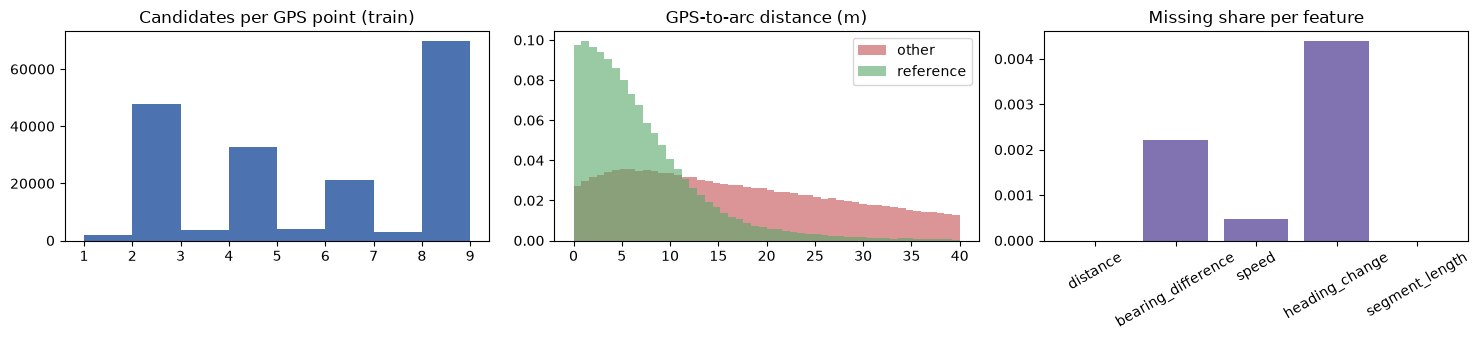

In [6]:
def miss_table(df, split):
    rows = []
    for tid, info in RAW[split].items():
        if tid not in set(df.trip_id):
            continue
        g = df[df.trip_id == tid]
        with_pos = g.groupby("gps_index")[TARGET].max().sum()
        rows.append(dict(trip_id=tid, gps_points=info["n_gps"], points_with_reference=int(with_pos)))
    t = pd.DataFrame(rows)
    t["candidate_miss_rate"] = 1 - t.points_with_reference / t.gps_points
    return t

miss_tr, miss_te = miss_table(train_raw, "train"), miss_table(test_raw, "test")
for name, t in [("training", miss_tr), ("student-test", miss_te)]:
    overall = 1 - t.points_with_reference.sum() / t.gps_points.sum()
    print(f"{name:13s} candidate miss rate = {overall:.2%} "
          f"(median per trip {t.candidate_miss_rate.median():.2%}, worst {t.candidate_miss_rate.max():.2%})")
MISS_RATE = {"train": 1 - miss_tr.points_with_reference.sum() / miss_tr.gps_points.sum(),
             "test": 1 - miss_te.points_with_reference.sum() / miss_te.gps_points.sum()}
print("\nWorst training trips by miss rate:")
display(miss_tr.sort_values("candidate_miss_rate", ascending=False).head(6))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
cpp = train_raw.groupby(["trip_id", "gps_index"]).size()
ax[0].hist(cpp, bins=range(1, cpp.max() + 2), color="#4C72B0"); ax[0].set_title("Candidates per GPS point (train)")
for lab, c in [(0, "#C44E52"), (1, "#55A868")]:
    ax[1].hist(train_raw.loc[train_raw[TARGET] == lab, "distance"], bins=50, alpha=.6, density=True, color=c,
               label="reference" if lab else "other")
ax[1].set_title("GPS-to-arc distance (m)"); ax[1].legend()
ax[2].bar(BASE_FEATURES, train_raw[BASE_FEATURES].isna().mean(), color="#8172B2")
ax[2].set_title("Missing share per feature"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "data_inspection.png"), dpi=130); plt.show()

## 5. Feature engineering

The same function is applied to the training and student-test tables. All features are computed
from a trip's own candidate rows, its neighbouring GPS points' candidates and its road graph —
no labels and no `.route` information are used.

| Group | Features | Why |
|---|---|---|
| Base | distance, bearing_difference, speed, heading_change, segment_length | geometry and motion |
| Within-point (relative) | n_candidates, dist_rank, dist_minus_min, dist_ratio_min, dist_softmax, bear_rank, bear_minus_min, is_nearest | the model chooses *among* candidates, so how a candidate compares to its rivals matters more than raw values |
| Neighbour context | in_prev_cands, in_next_cands, is_prev_nearest, is_next_nearest, from_prev_nearest, to_next_nearest, gps_step_prev, gps_step_next | a vehicle stays on the same or a connected arc between consecutive observations |
| Direction (windowed) | along_motion_m, along_motion_norm, win_bearing_diff, window_disp_m, win_bd_rank | the 1-second GPS heading is noise at low speed; direction is measured over the smallest window of GPS points that moved ≥ 25 m and compared with the arc's direction |
| Position on the arc | proj_t, beyond_end_m, before_start_m, span_pen, span_pen_rank, signed_offset_m | near a junction several arcs are equally close; whether the point lies inside the arc's span (or already past its end) tells the incoming arc from the outgoing one |

In [7]:
def add_features(df, raw):
    df = df.copy()
    keys = ["trip_id", "gps_index"]
    g = df.groupby(keys, sort=False)
    df["n_candidates"] = g["distance"].transform("size")
    df["dist_rank"] = g["distance"].rank(method="first")
    dmin = g["distance"].transform("min")
    df["dist_minus_min"] = df["distance"] - dmin
    df["dist_ratio_min"] = (df["distance"] + 1.0) / (dmin + 1.0)
    w = np.exp(-df["dist_minus_min"] / 10.0)
    df["dist_softmax"] = w / w.groupby([df.trip_id, df.gps_index]).transform("sum")
    df["bear_rank"] = g["bearing_difference"].rank(method="min")
    df["bear_minus_min"] = df["bearing_difference"] - g["bearing_difference"].transform("min")
    df["is_nearest"] = (df["dist_rank"] == 1).astype(int)

    # neighbouring observed GPS points (points without candidates are skipped)
    pts = df[keys].drop_duplicates().sort_values(keys)
    pts["prev_gps"] = pts.groupby("trip_id")["gps_index"].shift(1)
    pts["next_gps"] = pts.groupby("trip_id")["gps_index"].shift(-1)
    nearest = df.loc[df.is_nearest == 1, keys + ["candidate_arc_id"]].rename(columns={"candidate_arc_id": "nearest_arc"})
    pts = pts.merge(nearest.rename(columns={"gps_index": "prev_gps", "nearest_arc": "prev_nearest"}), on=["trip_id", "prev_gps"], how="left")
    pts = pts.merge(nearest.rename(columns={"gps_index": "next_gps", "nearest_arc": "next_nearest"}), on=["trip_id", "next_gps"], how="left")
    df = df.merge(pts, on=keys, how="left")

    cand = df[keys + ["candidate_arc_id"]].assign(_hit=1)
    df = df.merge(cand.rename(columns={"gps_index": "prev_gps", "_hit": "in_prev_cands"}),
                  on=["trip_id", "prev_gps", "candidate_arc_id"], how="left")
    df = df.merge(cand.rename(columns={"gps_index": "next_gps", "_hit": "in_next_cands"}),
                  on=["trip_id", "next_gps", "candidate_arc_id"], how="left")
    df[["in_prev_cands", "in_next_cands"]] = df[["in_prev_cands", "in_next_cands"]].fillna(0)
    df["is_prev_nearest"] = (df.candidate_arc_id == df.prev_nearest).astype(int)
    df["is_next_nearest"] = (df.candidate_arc_id == df.next_nearest).astype(int)
    df["gps_step_prev"] = df.gps_index - df.prev_gps
    df["gps_step_next"] = df.next_gps - df.gps_index

    # road connectivity: arc follows the previous nearest arc / leads into the next nearest arc
    from_prev = np.zeros(len(df), dtype=int)
    to_next = np.zeros(len(df), dtype=int)
    for tid, idx in df.groupby("trip_id").indices.items():
        frm, to = raw[tid]["frm"], raw[tid]["to"]
        a = df.candidate_arc_id.values[idx]
        pn, nn = df.prev_nearest.values[idx], df.next_nearest.values[idx]
        ok_p, ok_n = ~np.isnan(pn), ~np.isnan(nn)
        from_prev[idx[ok_p]] = ((to[pn[ok_p].astype(int)] == frm[a[ok_p]]) | (pn[ok_p].astype(int) == a[ok_p])).astype(int)
        to_next[idx[ok_n]] = ((to[a[ok_n]] == frm[nn[ok_n].astype(int)]) | (nn[ok_n].astype(int) == a[ok_n])).astype(int)
    df["from_prev_nearest"], df["to_next_nearest"] = from_prev, to_next
    df = df.drop(columns=["prev_gps", "next_gps", "prev_nearest", "next_nearest"])
    return df.sort_values(["trip_id", "gps_index", "candidate_arc_id"]).reset_index(drop=True)

def window_vectors(P, min_disp=25.0, kmax=20):
    # displacement over the smallest symmetric window (i-k .. i+k) that moved >= min_disp metres
    n = len(P); V = np.zeros((n, 2)); done = np.zeros(n, bool); idx = np.arange(n)
    for k in range(1, kmax + 1):
        a, b = np.clip(idx - k, 0, n - 1), np.clip(idx + k, 0, n - 1); v = P[b] - P[a]
        ok = (~done) & (np.hypot(v[:, 0], v[:, 1]) >= min_disp); V[ok] = v[ok]; done |= ok
    a, b = np.clip(idx - kmax, 0, n - 1), np.clip(idx + kmax, 0, n - 1); V[~done] = (P[b] - P[a])[~done]
    return V

def add_geometry_features(df, raw):
    cols = ["along_motion_m", "win_bearing_diff", "window_disp_m", "proj_t", "beyond_end_m", "before_start_m",
            "signed_offset_m", "pos_m"]
    out = {c: np.full(len(df), np.nan) for c in cols}
    for tid, idx in df.groupby("trip_id").indices.items():
        r = raw[tid]; V = window_vectors(r["P"])
        gi = df.gps_index.values[idx]; a = df.candidate_arc_id.values[idx]
        A, B = r["N"][r["frm"][a]], r["N"][r["to"][a]]; av = B - A
        L = np.maximum(np.hypot(av[:, 0], av[:, 1]), 1e-6); u = av / L[:, None]
        v = V[gi]; vn = np.hypot(v[:, 0], v[:, 1]); p = r["P"][gi]
        out["along_motion_m"][idx] = (v * u).sum(1)
        out["window_disp_m"][idx] = vn
        out["win_bearing_diff"][idx] = np.degrees(np.arccos(np.clip((v * u).sum(1) / np.maximum(vn, 1e-6), -1, 1)))
        t = ((p - A) * u).sum(1) / L
        out["proj_t"][idx] = t
        out["pos_m"][idx] = t * L                                   # position along the arc (used by the HMM)
        out["beyond_end_m"][idx] = np.maximum(0, (t - 1) * L)
        out["before_start_m"][idx] = np.maximum(0, -t * L)
        out["signed_offset_m"][idx] = u[:, 0] * (p - A)[:, 1] - u[:, 1] * (p - A)[:, 0]
    df = df.copy()
    for c in cols:
        df[c] = out[c]
    df["along_motion_norm"] = df.along_motion_m / np.maximum(df.window_disp_m, 1.0)
    df["span_pen"] = df.beyond_end_m + df.before_start_m
    g = df.groupby(["trip_id", "gps_index"], sort=False)
    df["win_bd_rank"] = g["win_bearing_diff"].rank(method="min")
    df["span_pen_rank"] = g["span_pen"].rank(method="min")
    return df

t0 = time.perf_counter()
train = add_geometry_features(add_features(train_raw, RAW["train"]), RAW["train"])
test = add_geometry_features(add_features(test_raw, RAW["test"]), RAW["test"])
FEATURES = BASE_FEATURES + ["n_candidates", "dist_rank", "dist_minus_min", "dist_ratio_min", "dist_softmax",
                            "bear_rank", "bear_minus_min", "is_nearest", "in_prev_cands", "in_next_cands",
                            "is_prev_nearest", "is_next_nearest", "from_prev_nearest", "to_next_nearest",
                            "gps_step_prev", "gps_step_next",
                            "along_motion_m", "along_motion_norm", "win_bearing_diff", "window_disp_m", "win_bd_rank",
                            "proj_t", "beyond_end_m", "before_start_m", "span_pen", "span_pen_rank", "signed_offset_m"]
KNN_FEATURES = ["distance", "dist_minus_min", "along_motion_norm", "win_bearing_diff", "span_pen",
                "is_prev_nearest", "is_next_nearest", "from_prev_nearest", "to_next_nearest"]
assert len(train) == len(train_raw) and len(test) == len(test_raw), "feature merge changed the row count"
assert not set(FEATURES) & set(META + [TARGET]), "ID or label used as a feature"
assert "pos_m" not in FEATURES  # absolute position is only used by the HMM
print(f"{len(FEATURES)} features built in {time.perf_counter()-t0:.1f}s")
display(train[FEATURES].describe().T[["mean", "std", "min", "max"]].round(3))

32 features built in 2.0s


,mean,std,min,max
distance,14.947,10.842,0.000,40.000
bearing_difference,87.450,61.509,0.000,180.000
speed,13.683,9.708,0.000,180.540
heading_change,67.870,54.542,0.000,180.000
segment_length,119.706,240.858,0.070,4671.058
n_candidates,6.448,2.104,1.000,8.000
dist_rank,3.724,2.204,1.000,8.000
dist_minus_min,9.605,10.561,0.000,39.976
dist_ratio_min,3.794,4.550,1.000,40.842
dist_softmax,0.191,0.173,0.003,1.000


## 6. Metrics

- **Observation-level Top-1 accuracy (primary metric)** — for each GPS point, the highest-scoring
  candidate is compared with the reference arc. This is exactly the map-matching decision, so it is
  used to select models; log loss is the tie-breaker because the HMM consumes the probabilities.
- Row-level accuracy / precision / recall / F1 / macro F1 / confusion matrix at threshold 0.5.
- **Route continuity** — share of consecutive predicted-arc changes that are physically connected
  (`to_node(previous) == from_node(next)`) in the directed road graph.

In [8]:
POINT = ["trip_id", "gps_index"]

def top1_choice(df, score):
    d = df[POINT + ["candidate_arc_id", TARGET]].copy()
    d["score"] = np.asarray(score)
    idx = d.groupby(POINT, sort=False)["score"].idxmax()
    return d.loc[idx].sort_values(POINT).reset_index(drop=True)

def route_continuity(choice, split):
    ok = total = 0
    for tid, g in choice.groupby("trip_id"):
        a = g.sort_values("gps_index")["candidate_arc_id"].to_numpy()
        frm, to = RAW[split][tid]["frm"], RAW[split][tid]["to"]
        ch = a[1:] != a[:-1]
        ok += int((to[a[:-1][ch]] == frm[a[1:][ch]]).sum()); total += int(ch.sum())
    return ok / total if total else 1.0

def compute_metrics(df, proba, split=None):
    y = df[TARGET].to_numpy(); p = np.clip(np.asarray(proba), 1e-7, 1 - 1e-7); yhat = (p >= 0.5).astype(int)
    ch = top1_choice(df, p)
    m = {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
         "recall": recall_score(y, yhat, zero_division=0), "f1": f1_score(y, yhat, zero_division=0),
         "macro_f1": f1_score(y, yhat, average="macro", zero_division=0),
         "log_loss": log_loss(y, p, labels=[0, 1]), "roc_auc": roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
         "top1_accuracy": ch[TARGET].mean()}
    if split is not None:
        m["route_continuity"] = route_continuity(ch, split)
    return m

# Non-ML reference point: always pick the nearest candidate
for name, df, split in [("training", train, "train"), ("student-test", test, "test")]:
    ch = top1_choice(df, -df["distance"].to_numpy())
    print(f"Nearest-candidate baseline ({name}): Top-1 = {ch[TARGET].mean():.4f}, "
          f"route continuity = {route_continuity(ch, split):.4f}")
BASELINE_TEST = top1_choice(test, -test["distance"].to_numpy())[TARGET].mean()

Nearest-candidate baseline (training): Top-1 = 0.5033, route continuity = 0.6192
Nearest-candidate baseline (student-test): Top-1 = 0.5045, route continuity = 0.6466


## 7. Train and evaluate seven models (seven algorithm families)

Each model: GroupKFold cross-validation on the 80 training trips (out-of-fold probabilities kept),
then one fit on all training trips and one evaluation on the 10 student-test trips.
Slow models (KNN, Random Forest, MLP) fit on a random sample of each fold's **training** rows
(`ROW_CAP`), recorded in the results — validation and test rows are never sampled away.

In [9]:
def imp():
    return SimpleImputer(strategy="median", add_indicator=True)

MODELS = {
    "logistic_regression": dict(family="Linear", features=FEATURES,
        make=lambda **p: Pipeline([("imp", imp()), ("sc", StandardScaler()),
                                   ("clf", LogisticRegression(max_iter=2000, C=p.get("C", 1.0), random_state=SEED))]),
        config="C=1.0, L2, lbfgs, standardised"),
    "gaussian_nb": dict(family="Probabilistic", features=FEATURES,
        make=lambda **p: Pipeline([("imp", imp()), ("clf", GaussianNB(var_smoothing=p.get("var_smoothing", 1e-9)))]),
        config="var_smoothing=1e-9"),
    "knn": dict(family="Instance-based", features=KNN_FEATURES,
        make=lambda **p: Pipeline([("imp", imp()), ("sc", StandardScaler()),
                                   ("clf", KNeighborsClassifier(n_neighbors=p.get("n_neighbors", 25), weights="distance", n_jobs=-1))]),
        config="k=25, distance-weighted, 9 standardised features"),
    "decision_tree": dict(family="Tree", features=FEATURES,
        make=lambda **p: Pipeline([("imp", imp()), ("clf", DecisionTreeClassifier(
            max_depth=p.get("max_depth", 12), min_samples_leaf=p.get("min_samples_leaf", 50), random_state=SEED))]),
        config="max_depth=12, min_samples_leaf=50"),
    "random_forest": dict(family="Ensemble (bagging)", features=FEATURES,
        make=lambda **p: Pipeline([("imp", imp()), ("clf", RandomForestClassifier(
            n_estimators=p.get("n_estimators", 150), max_depth=p.get("max_depth", 18),
            min_samples_leaf=p.get("min_samples_leaf", 5), max_features=p.get("max_features", "sqrt"),
            n_jobs=-1, random_state=SEED))]),
        config="150 trees, max_depth=18, min_samples_leaf=5"),
    "lightgbm": dict(family="Boosting", features=FEATURES,
        make=lambda **p: Pipeline([("imp", imp()), ("clf", LGBMClassifier(
            n_estimators=p.get("n_estimators", 400), learning_rate=p.get("learning_rate", 0.05),
            num_leaves=p.get("num_leaves", 63), min_child_samples=p.get("min_child_samples", 40),
            subsample=p.get("subsample", 0.8), subsample_freq=1, colsample_bytree=p.get("colsample_bytree", 0.8),
            reg_lambda=p.get("reg_lambda", 1.0), random_state=SEED, n_jobs=-1, verbose=-1))]),
        config="400 trees, lr=0.05, 63 leaves"),
    "mlp": dict(family="Neural network", features=FEATURES,
        make=lambda **p: Pipeline([("imp", imp()), ("sc", StandardScaler()), ("clf", MLPClassifier(
            hidden_layer_sizes=p.get("hidden_layer_sizes", (64, 32)), alpha=p.get("alpha", 1e-4),
            learning_rate_init=p.get("learning_rate_init", 1e-3), early_stopping=True, max_iter=60,
            random_state=SEED))]),
        config="hidden (64, 32), early stopping, standardised"),
}

def sample_rows(idx, cap, seed):
    if cap is None or len(idx) <= cap:
        return idx
    return np.sort(np.random.default_rng(seed).choice(idx, cap, replace=False))

def run_cv(name, params=None, n_splits=N_SPLITS, row_cap="default", data=None, quiet=False):
    spec, params = MODELS[name], params or {}
    data = train if data is None else data
    cap = ROW_CAP.get(name) if row_cap == "default" else row_cap
    X, y, groups = data[spec["features"]], data[TARGET], data["trip_id"]
    oof = np.full(len(data), np.nan); rows = []
    for fold, (tr, va) in enumerate(GroupKFold(n_splits=n_splits).split(X, y, groups)):
        assert set(groups.iloc[tr]).isdisjoint(groups.iloc[va]), "trip leakage between folds"
        fit_idx = sample_rows(tr, cap, SEED + fold)
        model = spec["make"](**params)
        t0 = time.perf_counter(); model.fit(X.iloc[fit_idx], y.iloc[fit_idx]); fit_s = time.perf_counter() - t0
        t0 = time.perf_counter(); p = model.predict_proba(X.iloc[va])[:, 1]; pred_s = time.perf_counter() - t0
        oof[va] = p
        m = compute_metrics(data.iloc[va], p); m.update(fold=fold, fit_s=fit_s, predict_s=pred_s, fit_rows=len(fit_idx))
        rows.append(m)
        if not quiet:
            print(f"  fold {fold}: top1={m['top1_accuracy']:.4f} macroF1={m['macro_f1']:.4f} "
                  f"logloss={m['log_loss']:.4f} (fit {fit_s:.1f}s on {len(fit_idx):,} rows)", flush=True)
    return pd.DataFrame(rows), oof

def fit_and_test(name, params=None):
    spec, params = MODELS[name], params or {}
    idx = sample_rows(np.arange(len(train)), ROW_CAP.get(name), SEED)
    model = spec["make"](**params)
    t0 = time.perf_counter(); model.fit(train[spec["features"]].iloc[idx], train[TARGET].iloc[idx]); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); p = model.predict_proba(test[spec["features"]])[:, 1]; pred_s = time.perf_counter() - t0
    m = compute_metrics(test, p, split="test")
    m.update(train_fit_s=fit_s, inference_s=pred_s, inference_ms_per_1k_rows=1000 * pred_s / len(test) * 1000)
    return model, p, m

In [10]:
RESULTS, CV_FOLDS, OOF, TEST_PROBA, FITTED = [], [], {}, {}, {}
for name, spec in MODELS.items():
    print(f"\n=== {name} ({spec['family']}) — {spec['config']}", flush=True)
    t_all = time.perf_counter()
    cv, oof = run_cv(name)
    model, p_test, tm = fit_and_test(name)
    cv["model"] = name; CV_FOLDS.append(cv); OOF[name] = oof; TEST_PROBA[name] = p_test; FITTED[name] = model
    row = {"model": name, "family": spec["family"], "config": spec["config"],
           "n_features": len(spec["features"]), "row_cap": ROW_CAP.get(name)}
    for k in ["top1_accuracy", "macro_f1", "f1", "precision", "recall", "accuracy", "log_loss", "roc_auc"]:
        row[f"cv_{k}"] = cv[k].mean(); row[f"cv_{k}_std"] = cv[k].std()
    row["cv_fit_s_mean"] = cv["fit_s"].mean()
    row["cv_route_continuity"] = route_continuity(top1_choice(train, oof), "train")
    for k, v in tm.items():
        row[f"test_{k}"] = v
    row["total_s"] = time.perf_counter() - t_all
    RESULTS.append(row)
    log_event("model", **{k: v for k, v in row.items() if not isinstance(v, float) or np.isfinite(v)})
    print(f"  -> CV top1 {row['cv_top1_accuracy']:.4f} ± {row['cv_top1_accuracy_std']:.4f} | "
          f"student-test top1 {tm['top1_accuracy']:.4f} | continuity {tm['route_continuity']:.4f} | {row['total_s']:.0f}s")

comparison = pd.DataFrame(RESULTS)
pd.concat(CV_FOLDS).to_csv(os.path.join(OUT_DIR, "cv_folds_all_models.csv"), index=False)
comparison.to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index=False)


=== logistic_regression (Linear) — C=1.0, L2, lbfgs, standardised
  fold 0: top1=0.7989 macroF1=0.8697 logloss=0.2169 (fit 3.3s on 772,671 rows)
  fold 1: top1=0.8623 macroF1=0.8970 logloss=0.1647 (fit 3.1s on 772,622 rows)
  fold 2: top1=0.8515 macroF1=0.8961 logloss=0.1822 (fit 2.8s on 772,651 rows)
  fold 3: top1=0.8030 macroF1=0.8724 logloss=0.1850 (fit 3.4s on 770,925 rows)
  fold 4: top1=0.7494 macroF1=0.8367 logloss=0.2129 (fit 2.9s on 772,607 rows)
  -> CV top1 0.8130 ± 0.0454 | student-test top1 0.8357 | continuity 0.7586 | 22s

=== gaussian_nb (Probabilistic) — var_smoothing=1e-9
  fold 0: top1=0.7835 macroF1=0.8334 logloss=1.3272 (fit 2.3s on 772,671 rows)
  fold 1: top1=0.8179 macroF1=0.8437 logloss=1.2121 (fit 2.3s on 772,622 rows)
  fold 2: top1=0.8319 macroF1=0.8386 logloss=1.3248 (fit 2.3s on 772,651 rows)
  fold 3: top1=0.7859 macroF1=0.8280 logloss=1.1948 (fit 2.3s on 770,925 rows)
  fold 4: top1=0.7274 macroF1=0.8128 logloss=1.3409 (fit 2.2s on 772,607 rows)
  -> CV

## 8. Model comparison and selection

**Selection rule (decided before looking at student-test results):** highest mean cross-validated
Top-1 accuracy on the 80 training trips; if two models are within one fold-standard-deviation, the
one with lower CV log loss wins (better probabilities for the HMM). Student-test columns are shown
for development comparison only.

,model,family,config,cv_top1_accuracy,cv_top1_accuracy_std,cv_macro_f1,cv_log_loss,test_top1_accuracy,test_precision,test_recall,test_f1,test_macro_f1,test_log_loss,test_route_continuity,cv_fit_s_mean,test_inference_s
0,lightgbm,Boosting,"400 trees, lr=0.05, 63 leaves",0.8432,0.0406,0.9020,0.1432,0.8530,0.8868,0.8253,0.8549,0.9118,0.1309,0.7349,11.9009,0.3210
1,mlp,Neural network,"hidden (64, 32), early stopping, standardised",0.8419,0.0394,0.8992,0.1507,0.8527,0.8916,0.8069,0.8471,0.9073,0.1353,0.7234,13.8520,0.0376
2,random_forest,Ensemble (bagging),"150 trees, max_depth=18, min_samples_leaf=5",0.8371,0.0430,0.8995,0.1458,0.8519,0.8973,0.8125,0.8528,0.9108,0.1314,0.7227,13.7744,0.1163
3,decision_tree,Tree,"max_depth=12, min_samples_leaf=50",0.8329,0.0401,0.8944,0.1761,0.8471,0.8729,0.8093,0.8399,0.9027,0.1674,0.7017,16.2982,0.0280
4,knn,Instance-based,"k=25, distance-weighted, 9 standardised features",0.8140,0.0449,0.8784,0.2777,0.8365,0.8388,0.8139,0.8262,0.8939,0.2317,0.7681,0.1571,1.5751
5,logistic_regression,Linear,"C=1.0, L2, lbfgs, standardised",0.8130,0.0454,0.8744,0.1923,0.8357,0.8290,0.8065,0.8176,0.8886,0.1727,0.7586,3.1182,0.0248
6,gaussian_nb,Probabilistic,var_smoothing=1e-9,0.7893,0.0403,0.8313,1.2800,0.8094,0.6334,0.8853,0.7384,0.8322,1.2192,0.7590,2.2975,0.0282


Selected for tuning and the HMM: lightgbm
Reason: best (or statistically tied best) CV Top-1 on the training trips; among ties, lowest CV log loss.


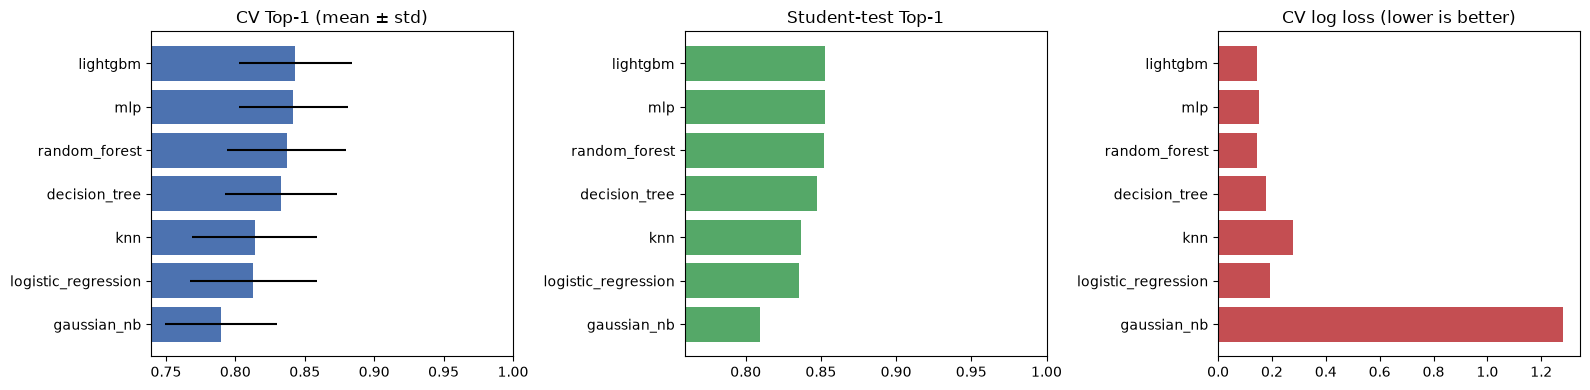

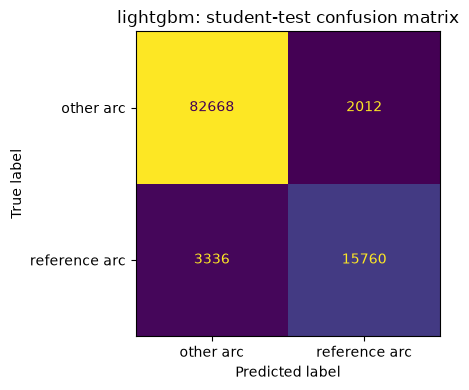

In [11]:
show = ["model", "family", "config", "cv_top1_accuracy", "cv_top1_accuracy_std", "cv_macro_f1", "cv_log_loss",
        "test_top1_accuracy", "test_precision", "test_recall", "test_f1", "test_macro_f1", "test_log_loss",
        "test_route_continuity", "cv_fit_s_mean", "test_inference_s"]
table = comparison[show].sort_values("cv_top1_accuracy", ascending=False).reset_index(drop=True)
display(table.round(4))

best = table.iloc[0]
close = table[table.cv_top1_accuracy >= best.cv_top1_accuracy - best.cv_top1_accuracy_std]
SELECTED = close.sort_values("cv_log_loss").iloc[0]["model"]
print(f"Selected for tuning and the HMM: {SELECTED}")
print("Reason: best (or statistically tied best) CV Top-1 on the training trips; among ties, lowest CV log loss.")
log_event("selection", selected=SELECTED, candidates_within_1std=list(close.model))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
t2 = table.sort_values("cv_top1_accuracy")
ax[0].barh(t2.model, t2.cv_top1_accuracy, xerr=t2.cv_top1_accuracy_std, color="#4C72B0"); ax[0].set_title("CV Top-1 (mean ± std)")
ax[0].set_xlim(max(0, t2.cv_top1_accuracy.min() - 0.05), 1)
ax[1].barh(t2.model, t2.test_top1_accuracy, color="#55A868"); ax[1].set_title("Student-test Top-1")
ax[1].set_xlim(max(0, t2.test_top1_accuracy.min() - 0.05), 1)
ax[2].barh(t2.model, t2.cv_log_loss, color="#C44E52"); ax[2].set_title("CV log loss (lower is better)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "model_comparison.png"), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
yhat = (TEST_PROBA[SELECTED] >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(test[TARGET], yhat), display_labels=["other arc", "reference arc"]).plot(ax=ax, colorbar=False)
ax.set_title(f"{SELECTED}: student-test confusion matrix"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"confusion_{SELECTED}.png"), dpi=130); plt.show()

## 9. Bayesian hyperparameter optimisation (Optuna TPE)

- **Model:** the selected model from section 8.
- **Objective:** maximise mean observation-level Top-1 accuracy under GroupKFold
  (`OPTUNA_FOLDS` folds) on the 80 training trips only.
- **Search space:** justified per model (capacity vs. regularisation); listed in the cell.
- The tuned configuration is refitted on all training trips, evaluated on the student-test trips and
  compared with the untuned model. The final model is the one with better **CV** Top-1 (not test).

  trial  0: top1=0.8432 params={'n_estimators': 400, 'learning_rate': 0.17854360608707254, 'num_leaves': 118, 'min_child_samples': 75, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.5779972601681014, 'reg_lambda': 0.0017073967431528124}
  trial  1: top1=0.8466 params={'n_estimators': 800, 'learning_rate': 0.07982611757123356, 'num_leaves': 111, 'min_child_samples': 10, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9162213204002109, 'reg_lambda': 0.0070689749506246055}
  trial  2: top1=0.8408 params={'n_estimators': 300, 'learning_rate': 0.03050945891610522, 'num_leaves': 35, 'min_child_samples': 58, 'subsample': 0.7727780074568463, 'colsample_bytree': 0.645614570099021, 'reg_lambda': 0.280163515871626}
  trial  3: top1=0.8424 params={'n_estimators': 300, 'learning_rate': 0.039189944117358336, 'num_leaves': 41, 'min_child_samples': 46, 'subsample': 0.9140703845572055, 'colsample_bytree': 0.5998368910791798, 'reg_lambda': 0.11400863701127326}
  trial  4: top1=0.8465 para

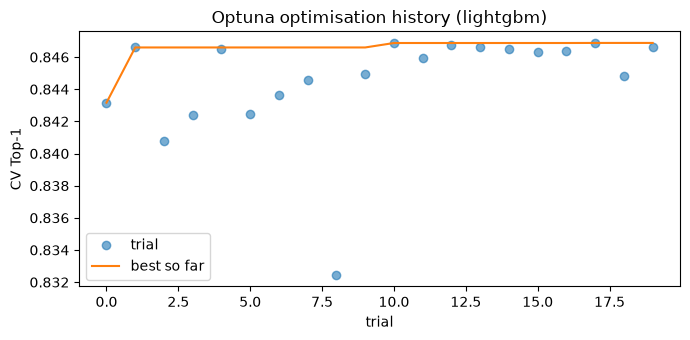

In [12]:
SPACES = {
    "lightgbm": lambda t: dict(
        n_estimators=t.suggest_int("n_estimators", 200, 900, step=100),      # more trees with lower lr
        learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True),
        num_leaves=t.suggest_int("num_leaves", 15, 255, log=True),            # tree complexity
        min_child_samples=t.suggest_int("min_child_samples", 10, 300, log=True),  # leaf-size regularisation
        subsample=t.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10.0, log=True)),
    "random_forest": lambda t: dict(
        n_estimators=t.suggest_int("n_estimators", 100, 300, step=50),
        max_depth=t.suggest_int("max_depth", 8, 30),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 50, log=True),
        max_features=t.suggest_categorical("max_features", ["sqrt", "log2", 0.5])),
    "decision_tree": lambda t: dict(max_depth=t.suggest_int("max_depth", 4, 30),
                                    min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 500, log=True)),
    "logistic_regression": lambda t: dict(C=t.suggest_float("C", 1e-3, 100, log=True)),
    "knn": lambda t: dict(n_neighbors=t.suggest_int("n_neighbors", 5, 101, step=2)),
    "gaussian_nb": lambda t: dict(var_smoothing=t.suggest_float("var_smoothing", 1e-12, 1e-2, log=True)),
    "mlp": lambda t: dict(hidden_layer_sizes=tuple(int(x) for x in t.suggest_categorical("hidden_layers", ["32", "64-32", "128-64", "128-64-32"]).split("-")),
                          alpha=t.suggest_float("alpha", 1e-6, 1e-2, log=True),
                          learning_rate_init=t.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True)),
}

def objective(trial):
    params = SPACES[SELECTED](trial)
    cap = min(OPTUNA_ROW_CAP, ROW_CAP.get(SELECTED) or OPTUNA_ROW_CAP)
    cv, _ = run_cv(SELECTED, params, n_splits=OPTUNA_FOLDS, row_cap=cap, quiet=True)
    trial.set_user_attr("cv_log_loss", float(cv.log_loss.mean()))
    trial.set_user_attr("fit_s", float(cv.fit_s.sum()))
    return float(cv.top1_accuracy.mean())

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            study_name=f"pathsnap_{SELECTED}")
t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False,
               callbacks=[lambda s, t: print(f"  trial {t.number:2d}: top1={t.value:.4f} params={t.params}", flush=True)])
TUNING_S = time.perf_counter() - t0
trials = study.trials_dataframe()
trials.to_csv(os.path.join(OUT_DIR, "optuna_trials.csv"), index=False)
BEST_PARAMS = SPACES[SELECTED](optuna.trial.FixedTrial(study.best_params))   # decoded (e.g. MLP layer sizes)
print(f"\nBest CV Top-1 during search: {study.best_value:.4f} with {BEST_PARAMS}")
print(f"Optimisation cost: {N_TRIALS} trials x {OPTUNA_FOLDS} folds in {TUNING_S/60:.1f} min")
log_event("optuna", model=SELECTED, n_trials=N_TRIALS, folds=OPTUNA_FOLDS, best_value=study.best_value,
          best_params={k: str(v) for k, v in BEST_PARAMS.items()}, seconds=TUNING_S)

plt.figure(figsize=(7, 3.5))
plt.plot(trials.number, trials.value, "o", alpha=.6, label="trial"); plt.plot(trials.number, trials.value.cummax(), "-", label="best so far")
plt.xlabel("trial"); plt.ylabel("CV Top-1"); plt.title(f"Optuna optimisation history ({SELECTED})"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "optuna_history.png"), dpi=130); plt.show()

Tuned model: full GroupKFold CV + student-test evaluation
  fold 0: top1=0.8253 macroF1=0.8940 logloss=0.1724 (fit 35.8s on 772,671 rows)
  fold 1: top1=0.8871 macroF1=0.9261 logloss=0.1169 (fit 34.3s on 772,622 rows)
  fold 2: top1=0.8778 macroF1=0.9196 logloss=0.1391 (fit 34.5s on 772,651 rows)
  fold 3: top1=0.8452 macroF1=0.9033 logloss=0.1347 (fit 34.1s on 770,925 rows)
  fold 4: top1=0.7903 macroF1=0.8720 logloss=0.1700 (fit 34.5s on 772,607 rows)


,untuned,tuned
cv_top1,0.8432,0.8452
cv_log_loss,0.1432,0.1466
test_top1,0.8530,0.8534
test_macro_f1,0.9118,0.9112
test_log_loss,0.1309,0.1333
test_route_continuity,0.7349,0.7314


Final classifier: lightgbm (tuned — chosen on CV Top-1)


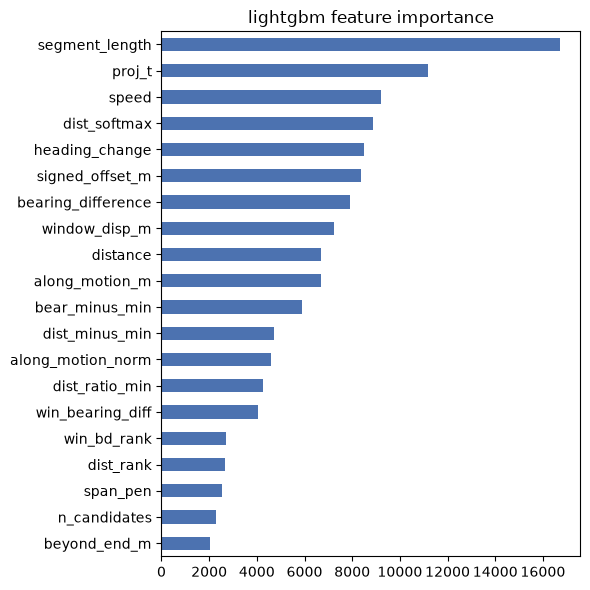

In [13]:
print("Tuned model: full GroupKFold CV + student-test evaluation")
cv_tuned, oof_tuned = run_cv(SELECTED, BEST_PARAMS)
model_tuned, p_test_tuned, tm_tuned = fit_and_test(SELECTED, BEST_PARAMS)
untuned = comparison.set_index("model").loc[SELECTED]
tuned_vs = pd.DataFrame({
    "untuned": {"cv_top1": untuned.cv_top1_accuracy, "cv_log_loss": untuned.cv_log_loss,
                "test_top1": untuned.test_top1_accuracy, "test_macro_f1": untuned.test_macro_f1,
                "test_log_loss": untuned.test_log_loss, "test_route_continuity": untuned.test_route_continuity},
    "tuned": {"cv_top1": cv_tuned.top1_accuracy.mean(), "cv_log_loss": cv_tuned.log_loss.mean(),
              "test_top1": tm_tuned["top1_accuracy"], "test_macro_f1": tm_tuned["macro_f1"],
              "test_log_loss": tm_tuned["log_loss"], "test_route_continuity": tm_tuned["route_continuity"]}})
display(tuned_vs.round(4))
tuned_vs.to_csv(os.path.join(OUT_DIR, "tuned_vs_untuned.csv"))

USE_TUNED = cv_tuned.top1_accuracy.mean() > untuned.cv_top1_accuracy      # decided on CV, not test; ties keep the simpler default
FINAL_PARAMS = BEST_PARAMS if USE_TUNED else {}
FINAL_MODEL = model_tuned if USE_TUNED else FITTED[SELECTED]
FINAL_OOF = oof_tuned if USE_TUNED else OOF[SELECTED]
FINAL_TEST_P = p_test_tuned if USE_TUNED else TEST_PROBA[SELECTED]
print(f"Final classifier: {SELECTED} ({'tuned' if USE_TUNED else 'untuned'} — chosen on CV Top-1)")
joblib.dump(FINAL_MODEL, os.path.join(OUT_DIR, "final_model.joblib"))
log_event("final_model", model=SELECTED, tuned=bool(USE_TUNED))

clf = FINAL_MODEL.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    names = FINAL_MODEL.named_steps["imp"].get_feature_names_out(MODELS[SELECTED]["features"])
    imp_s = pd.Series(clf.feature_importances_, index=names).sort_values()
    imp_s.tail(20).plot.barh(figsize=(6, 6), color="#4C72B0", title=f"{SELECTED} feature importance")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "feature_importance.png"), dpi=130); plt.show()

## 10. HMM and Viterbi route reconstruction

**Hidden states:** at GPS observation *t*, the states are that observation's candidate arcs (each
state keeps its `candidate_arc_id`, so the candidate-to-road-segment correspondence is preserved).

**Emission:** `w · log P(reference | features)` from the final classifier.

**Transition** from arc *i* (observation *t−1*) to arc *j* (observation *t*), using the directed road graph:

| relation | condition | log-score |
|---|---|---|
| same arc | i = j | 0, minus `back_pen` per 10 m moved *backwards* along the arc (beyond 5 m of GPS noise) |
| successor | to(i) = from(j), not a U-turn | `next_pen` |
| U-turn | j is the reverse of i (from(j) = to(i) and to(j) = from(i)) | `uturn_pen` |
| two hops | an arc x with from(x) = to(i), to(x) = from(j) | `two_pen` |
| anything else (invalid / far) | — | `far_pen` (finite, so a path always exists) |

**GPS gaps:** penalties are multiplied by `1 / (1 + max(0, Δt − 1) / tau)` so longer gaps allow
bigger moves; if `Δt > gap_reset` seconds the transition is reset to uniform (no constraint).
Observations without candidates (candidate misses) are skipped; Δt is measured between the
observations that remain.

**Viterbi recurrence:** δ_t(j) = max_i [δ_{t−1}(i) + A(i, j)] + B_t(j), with back-pointers; the
decoded path gives one predicted arc for every observation that has candidates.

**Decoder tuning:** `w, next_pen, uturn_pen, two_pen, far_pen, back_pen, tau, gap_reset` are tuned with Optuna on
**training trips only**, using the classifier's **out-of-fold** probabilities (so the decoder never
sees probabilities from a model trained on the same trip).

In [14]:
def prepare_trips(df, proba, split):
    """Per trip: list of per-observation candidate arrays plus precomputed relation codes."""
    d = df[POINT + ["candidate_arc_id", TARGET, "pos_m"]].copy(); d["p"] = np.asarray(proba)
    trips = {}
    for tid, g in d.groupby("trip_id", sort=False):
        frm, to, tt = RAW[split][tid]["frm"], RAW[split][tid]["to"], RAW[split][tid]["t"]
        succ_to = defaultdict(set)                      # node -> nodes reachable with one arc
        for f_, t_ in zip(frm, to):
            succ_to[f_].add(t_)
        obs = [(gi, gg.candidate_arc_id.to_numpy(), gg.p.to_numpy(), gg[TARGET].to_numpy(), gg.pos_m.to_numpy())
               for gi, gg in g.groupby("gps_index", sort=True)]
        codes, dts, backs = [None], [0.0], [None]
        for k in range(1, len(obs)):
            a_prev, a_cur = obs[k - 1][1], obs[k][1]
            same = a_prev[:, None] == a_cur[None, :]
            nxt = to[a_prev][:, None] == frm[a_cur][None, :]
            two = np.array([[frm[b] in succ_to[to[a]] for b in a_cur] for a in a_prev])
            uturn = (to[a_prev][:, None] == frm[a_cur][None, :]) & (frm[a_prev][:, None] == to[a_cur][None, :])
            c = np.full(same.shape, 3, dtype=np.int8); c[two] = 2; c[nxt] = 1; c[uturn] = 4; c[same] = 0
            back = np.where(same, np.clip((obs[k - 1][4][:, None] - obs[k][4][None, :] - 5.0) / 10.0, 0, 3), 0.0)
            codes.append(c); backs.append(back); dts.append(float(tt[obs[k][0]] - tt[obs[k - 1][0]]))
        trips[tid] = dict(obs=obs, codes=codes, dts=dts, backs=backs)
    return trips

def viterbi_trip(trip, hp):
    pen = np.array([0.0, hp["next_pen"], hp["two_pen"], hp["far_pen"], hp["uturn_pen"]])
    obs = trip["obs"]
    delta = hp["w"] * np.log(np.clip(obs[0][2], 1e-6, 1)); back = [None]
    for k in range(1, len(obs)):
        dt = trip["dts"][k]
        if dt > hp["gap_reset"]:
            A = np.zeros(trip["codes"][k].shape)
        else:
            A = (pen[trip["codes"][k]] + hp["back_pen"] * trip["backs"][k]) / (1.0 + max(0.0, dt - 1.0) / hp["tau"])
        scores = delta[:, None] + A
        bp = scores.argmax(axis=0)
        delta = scores[bp, np.arange(scores.shape[1])] + hp["w"] * np.log(np.clip(obs[k][2], 1e-6, 1))
        back.append(bp)
    path = [int(delta.argmax())]
    for k in range(len(obs) - 1, 0, -1):
        path.append(int(back[k][path[-1]]))
    path.reverse()
    return [(obs[k][0], int(obs[k][1][s]), int(obs[k][3][s])) for k, s in enumerate(path)]

def decode(trips, hp):
    rows = [(tid, gi, arc, lab) for tid, tr in trips.items() for gi, arc, lab in viterbi_trip(tr, hp)]
    return pd.DataFrame(rows, columns=["trip_id", "gps_index", "candidate_arc_id", TARGET])

DEFAULT_HP = dict(w=1.0, next_pen=-0.5, uturn_pen=-6.0, two_pen=-2.0, far_pen=-8.0, back_pen=-1.0, tau=10.0, gap_reset=60.0)

# --- tune the decoder on training trips with out-of-fold probabilities
rng = np.random.default_rng(SEED)
tune_trips = sorted(rng.choice(sorted(train.trip_id.unique()), size=min(HMM_TUNE_TRIPS, train.trip_id.nunique()), replace=False))
mask = train.trip_id.isin(tune_trips).to_numpy()
t0 = time.perf_counter()
tune_struct = prepare_trips(train[mask], FINAL_OOF[mask], "train")
print(f"Prepared {len(tune_struct)} training trips for decoder tuning in {time.perf_counter()-t0:.1f}s")
print(f"Classifier-only OOF Top-1 on these trips: {top1_choice(train[mask], FINAL_OOF[mask])[TARGET].mean():.4f}")
print(f"HMM with default parameters:          {decode(tune_struct, DEFAULT_HP)[TARGET].mean():.4f}")

def hmm_objective(trial):
    hp = dict(w=trial.suggest_float("w", 0.2, 3.0, log=True),
              next_pen=trial.suggest_float("next_pen", -3.0, 0.0),
              uturn_pen=trial.suggest_float("uturn_pen", -20.0, -0.5),
              two_pen=trial.suggest_float("two_pen", -8.0, -0.2),
              back_pen=trial.suggest_float("back_pen", -6.0, 0.0),
              far_pen=trial.suggest_float("far_pen", -25.0, -2.0),
              tau=trial.suggest_float("tau", 1.0, 120.0, log=True),
              gap_reset=trial.suggest_float("gap_reset", 5.0, 600.0, log=True))
    return decode(tune_struct, hp)[TARGET].mean()

hmm_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
hmm_study.enqueue_trial(DEFAULT_HP)
t0 = time.perf_counter()
hmm_study.optimize(hmm_objective, n_trials=HMM_TRIALS,
                   callbacks=[lambda s, t: print(f"  hmm trial {t.number:2d}: top1={t.value:.4f}", flush=True)])
HMM_TUNE_S = time.perf_counter() - t0
HMM_HP = hmm_study.best_params
hmm_study.trials_dataframe().to_csv(os.path.join(OUT_DIR, "hmm_tuning_trials.csv"), index=False)
print(f"\nBest decoder parameters (training trips, OOF): {json.dumps({k: round(v, 4) for k, v in HMM_HP.items()})}")
print(f"Decoder tuning: {HMM_TRIALS} trials in {HMM_TUNE_S/60:.1f} min")
log_event("hmm_tuning", trips=len(tune_trips), trials=HMM_TRIALS, best=hmm_study.best_value,
          params=HMM_HP, seconds=HMM_TUNE_S)

Prepared 40 training trips for decoder tuning in 4.2s
Classifier-only OOF Top-1 on these trips: 0.8245
HMM with default parameters:          0.8385
  hmm trial  0: top1=0.8385
  hmm trial  1: top1=0.8441
  hmm trial  2: top1=0.8385
  hmm trial  3: top1=0.8466
  hmm trial  4: top1=0.8436
  hmm trial  5: top1=0.8438
  hmm trial  6: top1=0.8152
  hmm trial  7: top1=0.8237
  hmm trial  8: top1=0.8556
  hmm trial  9: top1=0.8361
  hmm trial 10: top1=0.8402
  hmm trial 11: top1=0.8386
  hmm trial 12: top1=0.8465
  hmm trial 13: top1=0.8492
  hmm trial 14: top1=0.8489
  hmm trial 15: top1=0.8540
  hmm trial 16: top1=0.8438
  hmm trial 17: top1=0.8481
  hmm trial 18: top1=0.8418
  hmm trial 19: top1=0.8520
  hmm trial 20: top1=0.8515
  hmm trial 21: top1=0.8531
  hmm trial 22: top1=0.8376
  hmm trial 23: top1=0.8484
  hmm trial 24: top1=0.8558
  hmm trial 25: top1=0.8517
  hmm trial 26: top1=0.8272
  hmm trial 27: top1=0.8514
  hmm trial 28: top1=0.8588
  hmm trial 29: top1=0.8585

Best decode

## 11. Classifier-only vs classifier + HMM on the student-test trips

- **Pointwise:** observation-level Top-1 accuracy (and end-to-end accuracy counting candidate misses as wrong).
- **Sequence-level:** per-trip accuracy; route recovery against the `.route` file — the predicted arc
  sequence (consecutive repeats merged) is compared with the reference route by longest common
  subsequence (LCS precision = LCS / predicted length, LCS recall = LCS / reference length).
- **Route continuity** and the number of disconnected jumps.

,method,top1_accuracy,end_to_end_accuracy,route_continuity,mean_trip_top1,worst_trip_top1,lcs_precision,lcs_recall,disconnected_jumps
0,nearest candidate (no ML),0.5045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,classifier only,0.8534,0.8505,0.7314,0.8797,0.6608,0.7096,0.9013,1270.0
2,classifier + HMM,0.8910,0.8880,0.9104,0.9093,0.7311,0.9822,0.9125,285.0


method,classifier + HMM,classifier only
trip_id,,
00000000,0.9652,0.9456
00000007,0.9941,0.9586
00000009,0.8874,0.8633
00000040,0.9291,0.9077
00000052,0.9695,0.9580
00000056,0.9282,0.8839
00000065,0.9140,0.8983
00000076,0.9120,0.8754
00000077,0.7311,0.6608


HMM preparation + decoding of 10 trips: 0.9s

Target >= 96% observation-level Top-1 on student-test: NOT MET (best = 89.10%)


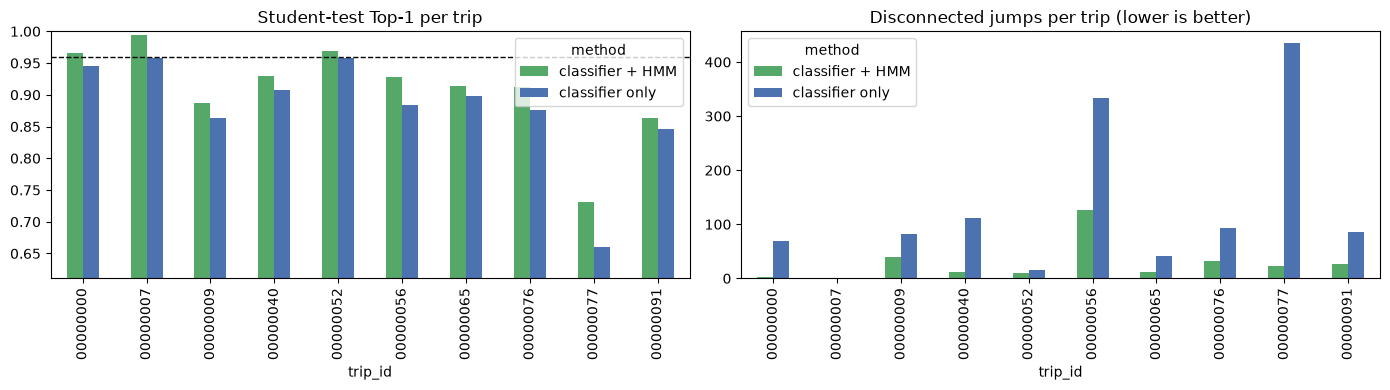

In [15]:
def lcs_len(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    return prev[-1]

def sequence_report(choice, split, label):
    rows = []
    for tid, g in choice.groupby("trip_id"):
        a = g.sort_values("gps_index")["candidate_arc_id"].to_numpy()
        seq = a[np.r_[True, a[1:] != a[:-1]]]
        ref = RAW[split][tid]["route"]
        frm, to = RAW[split][tid]["frm"], RAW[split][tid]["to"]
        ch = a[1:] != a[:-1]
        jumps = int((to[a[:-1][ch]] != frm[a[1:][ch]]).sum())
        L = lcs_len(list(seq), list(ref))
        rows.append(dict(trip_id=tid, method=label, points=len(g), top1=g[TARGET].mean(),
                         lcs_precision=L / len(seq), lcs_recall=L / len(ref), jumps=jumps,
                         continuity=1 - jumps / max(int(ch.sum()), 1)))
    return pd.DataFrame(rows)

t0 = time.perf_counter()
test_struct = prepare_trips(test, FINAL_TEST_P, "test")
clf_choice = top1_choice(test, FINAL_TEST_P)
hmm_choice = decode(test_struct, HMM_HP)
HMM_TEST_S = time.perf_counter() - t0

per_trip = pd.concat([sequence_report(clf_choice, "test", "classifier only"),
                      sequence_report(hmm_choice, "test", "classifier + HMM")])
per_trip.to_csv(os.path.join(OUT_DIR, "student_test_per_trip.csv"), index=False)

def overall(choice, label):
    return {"method": label, "top1_accuracy": choice[TARGET].mean(),
            "end_to_end_accuracy": choice[TARGET].sum() / sum(RAW["test"][t]["n_gps"] for t in set(test.trip_id)),
            "route_continuity": route_continuity(choice, "test"),
            "mean_trip_top1": per_trip[per_trip.method == label].top1.mean(),
            "worst_trip_top1": per_trip[per_trip.method == label].top1.min(),
            "lcs_precision": per_trip[per_trip.method == label].lcs_precision.mean(),
            "lcs_recall": per_trip[per_trip.method == label].lcs_recall.mean(),
            "disconnected_jumps": int(per_trip[per_trip.method == label].jumps.sum())}

final_table = pd.DataFrame([{"method": "nearest candidate (no ML)", "top1_accuracy": BASELINE_TEST},
                            overall(clf_choice, "classifier only"), overall(hmm_choice, "classifier + HMM")])
display(final_table.round(4))
final_table.to_csv(os.path.join(OUT_DIR, "classifier_vs_hmm_student_test.csv"), index=False)
display(per_trip.pivot(index="trip_id", columns="method", values="top1").round(4))
print(f"HMM preparation + decoding of {test.trip_id.nunique()} trips: {HMM_TEST_S:.1f}s")

best_top1 = final_table.top1_accuracy.max()
print(f"\nTarget >= {TARGET_TOP1:.0%} observation-level Top-1 on student-test: "
      f"{'MET' if best_top1 >= TARGET_TOP1 else 'NOT MET'} (best = {best_top1:.2%})")
log_event("final_evaluation", **{r["method"]: {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                                                for k, v in r.items()} for r in final_table.to_dict("records")})

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pv = per_trip.pivot(index="trip_id", columns="method", values="top1")
pv.plot.bar(ax=ax[0], color=["#55A868", "#4C72B0"]); ax[0].set_title("Student-test Top-1 per trip")
ax[0].set_ylim(max(0, pv.min().min() - 0.05), 1); ax[0].axhline(TARGET_TOP1, ls="--", c="k", lw=1)
pj = per_trip.pivot(index="trip_id", columns="method", values="jumps")
pj.plot.bar(ax=ax[1], color=["#55A868", "#4C72B0"]); ax[1].set_title("Disconnected jumps per trip (lower is better)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "classifier_vs_hmm.png"), dpi=130); plt.show()

## 12. Save artifacts and download

Everything is written to `pathsnap_results/` and downloaded as `pathsnap_results.zip`
(Colab deletes uploaded and generated files when the runtime resets).

In [16]:
config = {
    "seed": SEED, "profile": PROFILE, "settings": {k: (v if not isinstance(v, dict) else v) for k, v in CFG.items()},
    "files": {k: os.path.basename(v) for k, v in paths.items()},
    "features": FEATURES, "knn_features": KNN_FEATURES,
    "models": {n: {"family": s["family"], "config": s["config"]} for n, s in MODELS.items()},
    "selection_rule": "highest mean CV Top-1 on training trips; ties within 1 std broken by lower CV log loss",
    "selected_model": SELECTED, "tuned": bool(USE_TUNED),
    "final_params": {k: str(v) for k, v in FINAL_PARAMS.items()},
    "hmm": {"params": HMM_HP, "tuned_on_training_trips": [str(t) for t in tune_trips],
            "transition": "same=0 (+back_pen per 10 m backwards), successor=next_pen, U-turn=uturn_pen, two-hop=two_pen, other=far_pen; scaled by 1/(1+max(0,dt-1)/tau); reset if dt>gap_reset",
            "emission": "w * log(p)"},
    "candidate_miss_rate": MISS_RATE,
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "lightgbm": lightgbm.__version__, "optuna": optuna.__version__},
}
with open(os.path.join(OUT_DIR, "config.json"), "w") as fh:
    json.dump(config, fh, indent=2, default=str)
with open(os.path.join(OUT_DIR, "experiment_log.json"), "w") as fh:
    json.dump(EXPERIMENT_LOG, fh, indent=2, default=str)
joblib.dump({"hmm_params": HMM_HP, "features": FEATURES}, os.path.join(OUT_DIR, "hmm_config.joblib"))
out = test[META + [TARGET]].assign(probability=FINAL_TEST_P)
out.to_csv(os.path.join(OUT_DIR, "student_test_candidate_probabilities.csv"), index=False)
hmm_choice.rename(columns={"candidate_arc_id": "hmm_arc"}).merge(
    clf_choice.rename(columns={"candidate_arc_id": "classifier_arc"})[["trip_id", "gps_index", "classifier_arc"]],
    on=["trip_id", "gps_index"]).to_csv(os.path.join(OUT_DIR, "student_test_predicted_route.csv"), index=False)

zip_path = os.path.join(DATA_DIR, "pathsnap_results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT_DIR)):
        z.write(os.path.join(OUT_DIR, f), f)
print("Saved:", *sorted(os.listdir(OUT_DIR)), sep="\n  ")
if IN_COLAB:
    colab_files.download(zip_path)

Saved:
  classifier_vs_hmm.png
  classifier_vs_hmm_student_test.csv
  config.json
  confusion_lightgbm.png
  cv_folds_all_models.csv
  data_inspection.png
  experiment_log.json
  feature_importance.png
  final_model.joblib
  hmm_config.joblib
  hmm_tuning_trials.csv
  model_comparison.csv
  model_comparison.png
  optuna_history.png
  optuna_trials.csv
  student_test_candidate_probabilities.csv
  student_test_per_trip.csv
  student_test_predicted_route.csv
  tuned_vs_untuned.csv


## 13. Observations (write from the numbers above)

- Which model family performed best on CV Top-1, and was it stable across folds?
- Did Bayesian optimisation help on CV, and on the student-test trips?
- How much did the HMM change Top-1, route continuity and disconnected jumps? On which trips did it help or hurt?
- How large is the candidate miss rate, and what does it imply for end-to-end accuracy?
- Why is the final model compatible with the sequential decoder (probability quality, speed)?

In [18]:
%pip install -q networkx


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
distance_hmm_cell.py

NameError: name 'distance_hmm_cell' is not defined

In [20]:

# ===== 11b. Distance-aware HMM (Newson & Krumm transition model) =====
# Runs after section 11 and reuses what is already in memory: train, test, RAW, FINAL_OOF, FINAL_TEST_P,
# tune_trips, mask, top1_choice, route_continuity, sequence_report. Nothing is retrained.
import networkx as nx

GAP_DIST_M = 250.0      # GPS displacement above which consecutive observations are treated as a gap
SP_CUTOFF_M = 750.0     # shortest-path search radius on the road network

def build_trip_graph(r):
    L = np.hypot(*(r["N"][r["to"]] - r["N"][r["frm"]]).T)
    G = nx.DiGraph()
    G.add_weighted_edges_from(zip(r["frm"].tolist(), r["to"].tolist(), L.tolist()))
    return G, L

def prepare_trips_dist(df, proba, split):
    """Per trip: candidates per observation + network distances between consecutive candidates."""
    d = df[POINT + ["candidate_arc_id", TARGET, "pos_m"]].copy(); d["p"] = np.asarray(proba)
    trips = {}
    for tid, g in d.groupby("trip_id", sort=False):
        r = RAW[split][tid]; G, L = build_trip_graph(r); cache = {}
        def sp_from(node):
            if node not in cache:
                cache[node] = nx.single_source_dijkstra_path_length(G, node, cutoff=SP_CUTOFF_M)
            return cache[node]
        obs = []
        for gi, gg in g.groupby("gps_index", sort=True):
            a = gg.candidate_arc_id.to_numpy()
            obs.append((gi, a, gg.p.to_numpy(), gg[TARGET].to_numpy(), np.clip(gg.pos_m.to_numpy(), 0, L[a])))
        route_d, uturn, gps_d, dts = [None], [None], [0.0], [0.0]
        for k in range(1, len(obs)):
            (g0, a0, _, _, s0), (g1, a1, _, _, s1) = obs[k - 1], obs[k]
            D = np.full((len(a0), len(a1)), np.inf)
            for i, (ai, si) in enumerate(zip(a0, s0)):
                reach = sp_from(int(r["to"][ai]))
                for j, (aj, sj) in enumerate(zip(a1, s1)):
                    if ai == aj:
                        D[i, j] = max(sj - si, 0.0) if sj >= si - 10.0 else np.inf   # no driving backwards
                    else:
                        sp = reach.get(int(r["frm"][aj]))
                        if sp is not None:
                            D[i, j] = (L[ai] - si) + sp + sj
            route_d.append(D)
            uturn.append((r["to"][a0][:, None] == r["frm"][a1][None, :]) & (r["frm"][a0][:, None] == r["to"][a1][None, :]))
            gps_d.append(float(np.hypot(*(r["P"][g1] - r["P"][g0]))))
            dts.append(float(r["t"][g1] - r["t"][g0]))
        trips[tid] = dict(obs=obs, route_d=route_d, uturn=uturn, gps_d=gps_d, dts=dts)
    return trips

def viterbi_dist(trip, hp):
    obs = trip["obs"]
    delta = hp["w"] * np.log(np.clip(obs[0][2], 1e-6, 1)); back = [None]
    for k in range(1, len(obs)):
        if trip["dts"][k] > hp["gap_reset"] or trip["gps_d"][k] > GAP_DIST_M:
            A = np.zeros(trip["route_d"][k].shape)                       # GPS gap: unconstrained
        else:
            D = trip["route_d"][k]
            A = np.where(np.isfinite(D), -np.abs(np.nan_to_num(D, posinf=0.0) - trip["gps_d"][k]) / hp["beta"], hp["far_pen"])
            A = A + hp["uturn_pen"] * trip["uturn"][k]
        scores = delta[:, None] + A
        bp = scores.argmax(axis=0)
        delta = scores[bp, np.arange(scores.shape[1])] + hp["w"] * np.log(np.clip(obs[k][2], 1e-6, 1))
        back.append(bp)
    path = [int(delta.argmax())]
    for k in range(len(obs) - 1, 0, -1):
        path.append(int(back[k][path[-1]]))
    path.reverse()
    return [(obs[k][0], int(obs[k][1][s]), int(obs[k][3][s])) for k, s in enumerate(path)]

def decode_dist(trips, hp):
    rows = [(tid, gi, arc, lab) for tid, tr in trips.items() for gi, arc, lab in viterbi_dist(tr, hp)]
    return pd.DataFrame(rows, columns=["trip_id", "gps_index", "candidate_arc_id", TARGET])

# --- tune on training trips (out-of-fold probabilities) only
t0 = time.perf_counter()
tune_struct2 = prepare_trips_dist(train[mask], FINAL_OOF[mask], "train")
print(f"Prepared {len(tune_struct2)} training trips (network distances) in {time.perf_counter()-t0:.0f}s", flush=True)
HP2_DEFAULT = dict(w=1.0, beta=20.0, uturn_pen=-5.0, far_pen=-15.0, gap_reset=60.0)
print(f"Distance-aware HMM, default parameters, training trips: {decode_dist(tune_struct2, HP2_DEFAULT)[TARGET].mean():.4f}")

def hmm2_objective(trial):
    hp = dict(w=trial.suggest_float("w", 0.2, 3.0, log=True),
              beta=trial.suggest_float("beta", 2.0, 200.0, log=True),      # tolerance on |route - GPS| distance (m)
              uturn_pen=trial.suggest_float("uturn_pen", -20.0, 0.0),
              far_pen=trial.suggest_float("far_pen", -40.0, -2.0),
              gap_reset=trial.suggest_float("gap_reset", 5.0, 300.0, log=True))
    return decode_dist(tune_struct2, hp)[TARGET].mean()

hmm2_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
hmm2_study.enqueue_trial(HP2_DEFAULT)
t0 = time.perf_counter()
hmm2_study.optimize(hmm2_objective, n_trials=max(HMM_TRIALS, 20),
                    callbacks=[lambda s, t: print(f"  trial {t.number:2d}: top1={t.value:.4f}", flush=True)])
HMM2_HP = hmm2_study.best_params
HMM2_TUNE_S = time.perf_counter() - t0
hmm2_study.trials_dataframe().to_csv(os.path.join(OUT_DIR, "hmm_distance_tuning_trials.csv"), index=False)
print(f"Best (training trips, OOF): {hmm2_study.best_value:.4f} with {json.dumps({k: round(v, 3) for k, v in HMM2_HP.items()})}")

# --- evaluate once on the student-test trips
t0 = time.perf_counter()
test_struct2 = prepare_trips_dist(test, FINAL_TEST_P, "test")
hmm2_choice = decode_dist(test_struct2, HMM2_HP)
HMM2_TEST_S = time.perf_counter() - t0
per_trip2 = pd.concat([per_trip, sequence_report(hmm2_choice, "test", "classifier + distance HMM")])
per_trip2.to_csv(os.path.join(OUT_DIR, "student_test_per_trip_all_methods.csv"), index=False)

def overall2(choice, label, pt):
    s = pt[pt.method == label]
    return {"method": label, "top1_accuracy": choice[TARGET].mean(),
            "end_to_end_accuracy": choice[TARGET].sum() / sum(RAW["test"][t]["n_gps"] for t in set(test.trip_id)),
            "route_continuity": route_continuity(choice, "test"), "mean_trip_top1": s.top1.mean(),
            "worst_trip_top1": s.top1.min(), "lcs_precision": s.lcs_precision.mean(),
            "lcs_recall": s.lcs_recall.mean(), "disconnected_jumps": int(s.jumps.sum())}

final_table2 = pd.DataFrame([{"method": "nearest candidate (no ML)", "top1_accuracy": BASELINE_TEST},
                             overall2(clf_choice, "classifier only", per_trip2),
                             overall2(hmm_choice, "classifier + HMM", per_trip2),
                             overall2(hmm2_choice, "classifier + distance HMM", per_trip2)])
display(final_table2.round(4))
final_table2.to_csv(os.path.join(OUT_DIR, "classifier_vs_hmm_vs_distance_hmm.csv"), index=False)
display(per_trip2.pivot(index="trip_id", columns="method", values="top1").round(4))
print(f"Distance HMM on {test.trip_id.nunique()} test trips: {HMM2_TEST_S:.1f}s; tuning {HMM2_TUNE_S/60:.1f} min")
best2 = final_table2.top1_accuracy.max()
print(f"\nTarget >= {TARGET_TOP1:.0%} observation-level Top-1 on student-test: "
      f"{'MET' if best2 >= TARGET_TOP1 else 'NOT MET'} (best = {best2:.2%})")
with open(os.path.join(OUT_DIR, "hmm_distance_config.json"), "w") as fh:
    json.dump({"params": HMM2_HP, "gap_dist_m": GAP_DIST_M, "sp_cutoff_m": SP_CUTOFF_M,
               "transition": "-|network distance - GPS distance| / beta; unreachable within cutoff or backwards on the same arc = far_pen; U-turn adds uturn_pen; reset if dt>gap_reset or GPS jump>gap_dist_m",
               "emission": "w * log(p)", "tuned_on_training_trips": [str(t) for t in tune_trips]}, fh, indent=2)
joblib.dump({"hmm_distance_params": HMM2_HP, "gap_dist_m": GAP_DIST_M, "sp_cutoff_m": SP_CUTOFF_M},
            os.path.join(OUT_DIR, "hmm_distance_config.joblib"))


Prepared 40 training trips (network distances) in 7s
Distance-aware HMM, default parameters, training trips: 0.8426
  trial  0: top1=0.8426
  trial  1: top1=0.8374
  trial  2: top1=0.8331
  trial  3: top1=0.8388
  trial  4: top1=0.8418
  trial  5: top1=0.8431
  trial  6: top1=0.8402
  trial  7: top1=0.8341
  trial  8: top1=0.8408
  trial  9: top1=0.8459
  trial 10: top1=0.8414
  trial 11: top1=0.8437
  trial 12: top1=0.8431
  trial 13: top1=0.8432
  trial 14: top1=0.8402
  trial 15: top1=0.8399
  trial 16: top1=0.8451
  trial 17: top1=0.8430
  trial 18: top1=0.8422
  trial 19: top1=0.8421
  trial 20: top1=0.8341
  trial 21: top1=0.8444
  trial 22: top1=0.8410
  trial 23: top1=0.8455
  trial 24: top1=0.8459
  trial 25: top1=0.8450
  trial 26: top1=0.8471
  trial 27: top1=0.8443
  trial 28: top1=0.8447
  trial 29: top1=0.8344
Best (training trips, OOF): 0.8471 with {"w": 0.324, "beta": 29.419, "uturn_pen": -19.759, "far_pen": -6.17, "gap_reset": 14.143}


,method,top1_accuracy,end_to_end_accuracy,route_continuity,mean_trip_top1,worst_trip_top1,lcs_precision,lcs_recall,disconnected_jumps
0,nearest candidate (no ML),0.5045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,classifier only,0.8534,0.8505,0.7314,0.8797,0.6608,0.7096,0.9013,1270.0
2,classifier + HMM,0.8910,0.8880,0.9104,0.9093,0.7311,0.9822,0.9125,285.0
3,classifier + distance HMM,0.8774,0.8745,0.8877,0.9040,0.6738,0.9463,0.9090,368.0


method,classifier + HMM,classifier + distance HMM,classifier only
trip_id,,,
00000000,0.9652,0.9548,0.9456
00000007,0.9941,0.9934,0.9586
00000009,0.8874,0.8884,0.8633
00000040,0.9291,0.9194,0.9077
00000052,0.9695,0.9809,0.9580
00000056,0.9282,0.9307,0.8839
00000065,0.9140,0.9166,0.8983
00000076,0.9120,0.9079,0.8754
00000077,0.7311,0.6738,0.6608


Distance HMM on 10 test trips: 1.7s; tuning 0.5 min

Target >= 96% observation-level Top-1 on student-test: NOT MET (best = 89.10%)


['./pathsnap_results/hmm_distance_config.joblib']

In [21]:

# ===== 11c. Two-stage context model (stacking) + HMM =====
# Runs after section 11 and reuses memory: train, test, RAW, FINAL_OOF (stage-1 out-of-fold probabilities
# on training trips), FINAL_TEST_P, FEATURES, BEST_PARAMS/FINAL_PARAMS, prepare_trips, decode, HMM_HP ...
# Stage 2 sees stage-1 probabilities of the same / connected arcs at neighbouring GPS points.
# Training uses ONLY out-of-fold stage-1 probabilities, so no trip ever sees probabilities from a model fitted on it.

def context_features(df, p, split):
    d = df[POINT + ["candidate_arc_id"]].copy(); d["p"] = np.asarray(p)
    frm = np.empty(len(d), dtype=np.int64); to = np.empty(len(d), dtype=np.int64)
    for tid, idx in d.groupby("trip_id").indices.items():
        a = d.candidate_arc_id.values[idx]; frm[idx] = RAW[split][tid]["frm"][a]; to[idx] = RAW[split][tid]["to"][a]
    d["frm"], d["to"] = frm, to
    g = d.groupby(POINT, sort=False)["p"]
    d["p_rank"] = g.rank(ascending=False, method="first")
    d["p_max"] = g.transform("max"); d["p_gap"] = d.p_max - d.p
    second = d[d.p_rank == 2].set_index(POINT)["p"].rename("p_second")
    d = d.merge(second, left_on=POINT, right_index=True, how="left"); d["p_second"] = d.p_second.fillna(0)
    d["p_margin"] = np.where(d.p_rank == 1, d.p - d.p_second, d.p - d.p_max)
    pts = d[POINT].drop_duplicates().sort_values(POINT)
    for k in (1, 2):
        pts[f"prev{k}"] = pts.groupby("trip_id")["gps_index"].shift(k)
        pts[f"next{k}"] = pts.groupby("trip_id")["gps_index"].shift(-k)
    d = d.merge(pts, on=POINT, how="left")
    same = d[["trip_id", "gps_index", "candidate_arc_id", "p"]]
    into = d.groupby(["trip_id", "gps_index", "to"])["p"].max().reset_index()      # best arc ending at node
    outof = d.groupby(["trip_id", "gps_index", "frm"])["p"].max().reset_index()    # best arc starting at node
    for k in (1, 2):
        d = d.merge(same.rename(columns={"gps_index": f"prev{k}", "p": f"prev{k}_same"}), on=["trip_id", f"prev{k}", "candidate_arc_id"], how="left")
        d = d.merge(same.rename(columns={"gps_index": f"next{k}", "p": f"next{k}_same"}), on=["trip_id", f"next{k}", "candidate_arc_id"], how="left")
        d = d.merge(into.rename(columns={"gps_index": f"prev{k}", "to": "frm", "p": f"prev{k}_into"}), on=["trip_id", f"prev{k}", "frm"], how="left")
        d = d.merge(outof.rename(columns={"gps_index": f"next{k}", "frm": "to", "p": f"next{k}_from"}), on=["trip_id", f"next{k}", "to"], how="left")
    cols = ["p", "p_rank", "p_gap", "p_margin"] + [f"{s}{k}_{t}" for k in (1, 2) for s, t in
                                                    [("prev", "same"), ("next", "same"), ("prev", "into"), ("next", "from")]]
    d[cols] = d[cols].fillna(0.0)
    for k in (1, 2):
        d[f"ctx{k}"] = np.maximum(d[f"prev{k}_same"], d[f"prev{k}_into"]) + np.maximum(d[f"next{k}_same"], d[f"next{k}_from"])
    cols += ["ctx1", "ctx2"]
    d = d.sort_values(POINT + ["candidate_arc_id"]).reset_index(drop=True)
    assert len(d) == len(df) and (d.candidate_arc_id.values == df.candidate_arc_id.values).all()
    return d[cols].set_axis(df.index)

t0 = time.perf_counter()
ctx_tr = context_features(train, FINAL_OOF, "train")
ctx_te = context_features(test, FINAL_TEST_P, "test")
STAGE2_FEATURES = FEATURES + list(ctx_tr.columns)
train2 = pd.concat([train, ctx_tr.add_prefix("s1_")], axis=1)
test2 = pd.concat([test, ctx_te.add_prefix("s1_")], axis=1)
S2_COLS = FEATURES + ["s1_" + c for c in ctx_tr.columns]
print(f"Context features built in {time.perf_counter()-t0:.0f}s ({len(ctx_tr.columns)} new)", flush=True)

lgb_params = FINAL_PARAMS if SELECTED == "lightgbm" and FINAL_PARAMS else {}
def make_stage2():
    return MODELS["lightgbm"]["make"](**lgb_params)

# out-of-fold stage-2 probabilities on training trips (for HMM tuning) + CV score
oof2 = np.full(len(train2), np.nan); s2_rows = []
for fold, (tr, va) in enumerate(GroupKFold(n_splits=N_SPLITS).split(train2, train2[TARGET], train2["trip_id"])):
    m = make_stage2(); t0 = time.perf_counter(); m.fit(train2[S2_COLS].iloc[tr], train2[TARGET].iloc[tr])
    oof2[va] = m.predict_proba(train2[S2_COLS].iloc[va])[:, 1]
    r = compute_metrics(train2.iloc[va], oof2[va]); s2_rows.append(r)
    print(f"  stage-2 fold {fold}: top1={r['top1_accuracy']:.4f} (fit {time.perf_counter()-t0:.0f}s)", flush=True)
stage2_model = make_stage2(); stage2_model.fit(train2[S2_COLS], train2[TARGET])
p2_test = stage2_model.predict_proba(test2[S2_COLS])[:, 1]
joblib.dump({"model": stage2_model, "features": S2_COLS}, os.path.join(OUT_DIR, "stage2_model.joblib"))
print(f"Stage-2 CV Top-1 {np.mean([r['top1_accuracy'] for r in s2_rows]):.4f} "
      f"(stage-1 CV Top-1 was {compute_metrics(train, FINAL_OOF)['top1_accuracy']:.4f})")

# HMM on stage-2 probabilities, re-tuned on the same training trips (out-of-fold) only
tune_s2 = prepare_trips(train2[mask], oof2[mask], "train")
def hmm_obj2(trial):
    hp = dict(w=trial.suggest_float("w", 0.2, 3.0, log=True), next_pen=trial.suggest_float("next_pen", -3.0, 0.0),
              uturn_pen=trial.suggest_float("uturn_pen", -20.0, -0.5), two_pen=trial.suggest_float("two_pen", -8.0, -0.2),
              back_pen=trial.suggest_float("back_pen", -6.0, 0.0), far_pen=trial.suggest_float("far_pen", -25.0, -2.0),
              tau=trial.suggest_float("tau", 1.0, 120.0, log=True), gap_reset=trial.suggest_float("gap_reset", 5.0, 600.0, log=True))
    return decode(tune_s2, hp)[TARGET].mean()
st2 = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
st2.enqueue_trial(HMM_HP)
st2.optimize(hmm_obj2, n_trials=max(HMM_TRIALS, 20))
HMM_HP_S2 = st2.best_params
print(f"Stage-2 HMM best on training trips (OOF): {st2.best_value:.4f}")

s2_choice = top1_choice(test2, p2_test)
s2_hmm_choice = decode(prepare_trips(test2, p2_test, "test"), HMM_HP_S2)
pt_all = pd.concat([per_trip, sequence_report(s2_choice, "test", "stage-2 only"),
                    sequence_report(s2_hmm_choice, "test", "stage-2 + HMM")])

def row_acc(p):
    return accuracy_score(test[TARGET], (np.asarray(p) >= 0.5).astype(int))
summary = pd.DataFrame([
    {"method": "nearest candidate (no ML)", "top1_accuracy": BASELINE_TEST},
    {"method": "classifier only", "top1_accuracy": clf_choice[TARGET].mean(), "row_level_accuracy": row_acc(FINAL_TEST_P),
     "route_continuity": route_continuity(clf_choice, "test")},
    {"method": "classifier + HMM", "top1_accuracy": hmm_choice[TARGET].mean(), "route_continuity": route_continuity(hmm_choice, "test")},
    {"method": "stage-2 only", "top1_accuracy": s2_choice[TARGET].mean(), "row_level_accuracy": row_acc(p2_test),
     "route_continuity": route_continuity(s2_choice, "test")},
    {"method": "stage-2 + HMM", "top1_accuracy": s2_hmm_choice[TARGET].mean(), "route_continuity": route_continuity(s2_hmm_choice, "test")},
])
display(summary.round(4))
summary.to_csv(os.path.join(OUT_DIR, "stage2_summary.csv"), index=False)
pt_all.to_csv(os.path.join(OUT_DIR, "student_test_per_trip_with_stage2.csv"), index=False)
display(pt_all.pivot(index="trip_id", columns="method", values="top1").round(4))
best3 = summary.top1_accuracy.max()
print(f"\nTarget >= {TARGET_TOP1:.0%} observation-level Top-1 on student-test: {'MET' if best3 >= TARGET_TOP1 else 'NOT MET'} (best = {best3:.2%})")
with open(os.path.join(OUT_DIR, "stage2_config.json"), "w") as fh:
    json.dump({"stage2_features": S2_COLS, "lightgbm_params": {k: str(v) for k, v in lgb_params.items()},
               "hmm_params": HMM_HP_S2, "note": "stage-1 probabilities for training rows are out-of-fold"}, fh, indent=2)


Context features built in 1s (14 new)
  stage-2 fold 0: top1=0.8486 (fit 39s)
  stage-2 fold 1: top1=0.9077 (fit 37s)
  stage-2 fold 2: top1=0.9012 (fit 38s)
  stage-2 fold 3: top1=0.8636 (fit 37s)
  stage-2 fold 4: top1=0.8294 (fit 38s)
Stage-2 CV Top-1 0.8701 (stage-1 CV Top-1 was 0.8472)
Stage-2 HMM best on training trips (OOF): 0.8696


,method,top1_accuracy,row_level_accuracy,route_continuity
0,nearest candidate (no ML),0.5045,NaN,NaN
1,classifier only,0.8534,0.9481,0.7314
2,classifier + HMM,0.8910,NaN,0.9104
3,stage-2 only,0.8758,0.9571,0.7793
4,stage-2 + HMM,0.8911,NaN,0.9279


method,classifier + HMM,classifier only,stage-2 + HMM,stage-2 only
trip_id,,,,
00000000,0.9652,0.9456,0.9788,0.9532
00000007,0.9941,0.9586,0.8848,0.9180
00000009,0.8874,0.8633,0.8797,0.8681
00000040,0.9291,0.9077,0.9331,0.9237
00000052,0.9695,0.9580,0.9046,0.9618
00000056,0.9282,0.8839,0.9223,0.9131
00000065,0.9140,0.8983,0.9231,0.9205
00000076,0.9120,0.8754,0.9255,0.9025
00000077,0.7311,0.6608,0.7572,0.7127



Target >= 96% observation-level Top-1 on student-test: NOT MET (best = 89.11%)


In [22]:
# Top-3 ensemble (average probabilities of the 3 best models by CV Top-1) + HMM re-tuned on training trips only
top3 = comparison.sort_values("cv_top1_accuracy", ascending=False).model.head(3).tolist()
oof_e = np.mean([FINAL_OOF if m == SELECTED else OOF[m] for m in top3], axis=0)
p_e = np.mean([FINAL_TEST_P if m == SELECTED else TEST_PROBA[m] for m in top3], axis=0)
print("Top-3 models:", top3)
print(f"Ensemble CV Top-1 (training trips, OOF): {top1_choice(train, oof_e)[TARGET].mean():.4f} | student-test Top-1 without HMM: {top1_choice(test, p_e)[TARGET].mean():.4f}")
ts = prepare_trips(train[mask], oof_e[mask], "train")
st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)); st.enqueue_trial(HMM_HP)
st.optimize(lambda t: decode(ts, dict(w=t.suggest_float("w", 0.2, 3, log=True), next_pen=t.suggest_float("next_pen", -3, 0),
    uturn_pen=t.suggest_float("uturn_pen", -20, -0.5), two_pen=t.suggest_float("two_pen", -8, -0.2),
    back_pen=t.suggest_float("back_pen", -6, 0), far_pen=t.suggest_float("far_pen", -25, -2),
    tau=t.suggest_float("tau", 1, 120, log=True), gap_reset=t.suggest_float("gap_reset", 5, 600, log=True)))[TARGET].mean(), n_trials=15)
ens_hmm = decode(prepare_trips(test, p_e, "test"), st.best_params)
print(f"Top-3 ensemble + HMM, student-test Top-1: {ens_hmm[TARGET].mean():.4f} | route continuity {route_continuity(ens_hmm, 'test'):.4f}")
pd.DataFrame([{"method": "top-3 ensemble + HMM", "models": "+".join(top3), "top1_accuracy": ens_hmm[TARGET].mean()}]).to_csv(os.path.join(OUT_DIR, "ensemble_top3_hmm.csv"), index=False)

Top-3 models: ['lightgbm', 'mlp', 'random_forest']
Ensemble CV Top-1 (training trips, OOF): 0.8461 | student-test Top-1 without HMM: 0.8549
Top-3 ensemble + HMM, student-test Top-1: 0.8860 | route continuity 0.9093


In [23]:
# LightGBM RANKER (lambdarank): learns to put the correct arc first among each GPS point's candidates.
# Out-of-fold scores on training trips (GroupKFold by trip) for HMM tuning; test trips used once.
from lightgbm import LGBMRanker
RANK_PARAMS = dict(objective="lambdarank", n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=40,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, lambdarank_truncation_level=3,
                   random_state=SEED, n_jobs=-1, verbose=-1)
def point_groups(df):
    return df.groupby(["trip_id", "gps_index"], sort=False).size().to_numpy()
def softmax_by_point(df, s):
    d = pd.DataFrame({"t": df.trip_id.values, "g": df.gps_index.values, "s": s})
    e = np.exp(d.s - d.groupby(["t", "g"]).s.transform("max"))
    return (e / e.groupby([d.t, d.g]).transform("sum")).to_numpy()
oof_r = np.zeros(len(train))
for fold, (tr, va) in enumerate(GroupKFold(n_splits=3).split(train, train[TARGET], train["trip_id"])):
    t0 = time.perf_counter(); rk = LGBMRanker(**RANK_PARAMS)
    rk.fit(train[FEATURES].iloc[tr], train[TARGET].iloc[tr], group=point_groups(train.iloc[tr]))
    oof_r[va] = softmax_by_point(train.iloc[va], rk.predict(train[FEATURES].iloc[va]))
    print(f"  ranker fold {fold}: top1={top1_choice(train.iloc[va], oof_r[va])[TARGET].mean():.4f} ({time.perf_counter()-t0:.0f}s)", flush=True)
ranker = LGBMRanker(**RANK_PARAMS).fit(train[FEATURES], train[TARGET], group=point_groups(train))
p_r = softmax_by_point(test, ranker.predict(test[FEATURES]))
joblib.dump(ranker, os.path.join(OUT_DIR, "lgbm_ranker.joblib"))
print(f"Ranker CV Top-1 (training trips): {top1_choice(train, oof_r)[TARGET].mean():.4f} | student-test Top-1 without HMM: {top1_choice(test, p_r)[TARGET].mean():.4f}")
ts_r = prepare_trips(train[mask], oof_r[mask], "train")
st_r = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)); st_r.enqueue_trial(HMM_HP)
st_r.optimize(lambda t: decode(ts_r, dict(w=t.suggest_float("w", 0.2, 3, log=True), next_pen=t.suggest_float("next_pen", -3, 0),
    uturn_pen=t.suggest_float("uturn_pen", -20, -0.5), two_pen=t.suggest_float("two_pen", -8, -0.2),
    back_pen=t.suggest_float("back_pen", -6, 0), far_pen=t.suggest_float("far_pen", -25, -2),
    tau=t.suggest_float("tau", 1, 120, log=True), gap_reset=t.suggest_float("gap_reset", 5, 600, log=True)))[TARGET].mean(), n_trials=15)
rank_hmm = decode(prepare_trips(test, p_r, "test"), st_r.best_params)
print(f"LightGBM ranker + HMM, student-test Top-1: {rank_hmm[TARGET].mean():.4f} | route continuity {route_continuity(rank_hmm, 'test'):.4f}")
pd.DataFrame([{"method": "LightGBM ranker + HMM", "top1_accuracy": rank_hmm[TARGET].mean(), "hmm_params": json.dumps(st_r.best_params)}]).to_csv(os.path.join(OUT_DIR, "ranker_hmm.csv"), index=False)

  ranker fold 0: top1=0.8485 (12s)
  ranker fold 1: top1=0.8213 (11s)
  ranker fold 2: top1=0.8775 (11s)
Ranker CV Top-1 (training trips): 0.8512 | student-test Top-1 without HMM: 0.8527
LightGBM ranker + HMM, student-test Top-1: 0.8877 | route continuity 0.9099


In [24]:
# VERIFY: is our 89% a bug, or a different definition of "accuracy"? (no training, runs in seconds)
from sklearn.metrics import accuracy_score
best_choice = hmm_choice                     # final method: classifier + HMM
route_sets = {t: set(RAW["test"][t]["route"].tolist()) for t in test.trip_id.unique()}
# 1) sanity checks on the evaluation itself
pts = test.groupby(POINT)[TARGET].sum()
print("Checks: points evaluated =", len(best_choice), "| test points with exactly one correct arc =", int((pts == 1).sum()),
      "| duplicates in predictions =", int(best_choice.duplicated(POINT).sum()))
# 2) the same predictions scored under the definitions other teams may be using
def in_route(ch): return np.mean([a in route_sets[t] for t, a in zip(ch.trip_id, ch.candidate_arc_id)])
def nearest_route_label_acc(ch):
    d = test[POINT + ["candidate_arc_id", "distance"]].copy()
    d = d[[a in route_sets[t] for t, a in zip(d.trip_id, d.candidate_arc_id)]]
    lab = d.loc[d.groupby(POINT).distance.idxmin(), POINT + ["candidate_arc_id"]].rename(columns={"candidate_arc_id": "nr"})
    m = ch.merge(lab, on=POINT, how="left"); return (m.candidate_arc_id == m.nr).mean()
rows = []
for name, ch, p in [("classifier only", clf_choice, FINAL_TEST_P), ("classifier + HMM", hmm_choice, None)]:
    rows.append({"method": name,
                 "Top-1 vs our labels (what we report)": ch[TARGET].mean(),
                 "predicted arc is on the reference route": in_route(ch),
                 "Top-1 vs 'nearest route arc' labels": nearest_route_label_acc(ch),
                 "row-level accuracy (sklearn accuracy_score)": accuracy_score(test[TARGET], (p >= 0.5).astype(int)) if p is not None else np.nan})
display(pd.DataFrame(rows).round(4))
# 3) what kind of mistakes remain (final method)
tru = test[test[TARGET] == 1][POINT + ["candidate_arc_id"]].rename(columns={"candidate_arc_id": "true_arc"})
e = best_choice[best_choice[TARGET] == 0].merge(tru, on=POINT)
def kind(r):
    R = RAW["test"][r.trip_id]; a, b = r.candidate_arc_id, r.true_arc
    if R["frm"][a] == R["to"][b] and R["to"][a] == R["frm"][b]: return "opposite direction, same road"
    if R["to"][a] == R["frm"][b] or R["to"][b] == R["frm"][a]: return "next/previous arc (junction boundary)"
    if a in route_sets[r.trip_id]: return "another arc of the route (route passes here twice?)"
    return "different road"
print(f"\nRemaining errors: {len(e):,} of {len(best_choice):,} points"); print(e.apply(kind, axis=1).value_counts(normalize=True).round(3).to_string())
print("\nTrip 77: points", (best_choice.trip_id == "00000077").sum(), "| route arcs", len(RAW["test"]["00000077"]["route"]),
      "| distinct route arcs", len(route_sets["00000077"]), "| errors there", (e.trip_id == "00000077").sum())

Checks: points evaluated = 19096 | test points with exactly one correct arc = 19096 | duplicates in predictions = 0


,method,Top-1 vs our labels (what we report),predicted arc is on the reference route,Top-1 vs 'nearest route arc' labels,row-level accuracy (sklearn accuracy_score)
0,classifier only,0.8534,0.9260,0.8337,0.9481
1,classifier + HMM,0.8910,0.9582,0.8559,NaN



Remaining errors: 2,081 of 19,096 points
next/previous arc (junction boundary)                  0.696
different road                                         0.184
opposite direction, same road                          0.104
another arc of the route (route passes here twice?)    0.016

Trip 77: points 3909 | route arcs 268 | distinct route arcs 268 | errors there 1051


In [25]:
# Combine the three strongest probability sources (tuned LightGBM, ranker, stage-2) and re-tune the HMM on ALL training trips.
# Training side uses only out-of-fold probabilities; the student-test trips are decoded once.
srcs_tr = [FINAL_OOF, oof_r, oof2]; srcs_te = [FINAL_TEST_P, p_r, p2_test]
oof_c = np.mean(srcs_tr, axis=0); p_c = np.mean(srcs_te, axis=0)
print(f"Combined CV Top-1 (training, OOF): {top1_choice(train, oof_c)[TARGET].mean():.4f} | student-test without HMM: {top1_choice(test, p_c)[TARGET].mean():.4f}", flush=True)
t0 = time.perf_counter(); ts_all = prepare_trips(train, oof_c, "train"); print(f"prepared all training trips in {time.perf_counter()-t0:.0f}s", flush=True)
space = lambda t: dict(w=t.suggest_float("w", 0.2, 3, log=True), next_pen=t.suggest_float("next_pen", -3, 0),
    uturn_pen=t.suggest_float("uturn_pen", -20, -0.5), two_pen=t.suggest_float("two_pen", -8, -0.2),
    back_pen=t.suggest_float("back_pen", -6, 0), far_pen=t.suggest_float("far_pen", -25, -2),
    tau=t.suggest_float("tau", 1, 120, log=True), gap_reset=t.suggest_float("gap_reset", 5, 600, log=True))
st_c = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
for hp in (HMM_HP, HMM_HP_S2, st_r.best_params): st_c.enqueue_trial(hp)
st_c.optimize(lambda t: decode(ts_all, space(t))[TARGET].mean(), n_trials=30,
              callbacks=[lambda s, t: print(f"  trial {t.number:2d}: train top1={t.value:.4f}", flush=True)])
combo_hmm = decode(prepare_trips(test, p_c, "test"), st_c.best_params)
print(f"\nCOMBINED + HMM, student-test Top-1: {combo_hmm[TARGET].mean():.4f} | route continuity {route_continuity(combo_hmm, 'test'):.4f} "
      f"| on-route {np.mean([a in route_sets[t] for t, a in zip(combo_hmm.trip_id, combo_hmm.candidate_arc_id)]):.4f}")
pd.DataFrame([{"method": "LightGBM+ranker+stage2 average + HMM (tuned on all 80 training trips)", "top1_accuracy": combo_hmm[TARGET].mean(),
               "hmm_params": json.dumps(st_c.best_params)}]).to_csv(os.path.join(OUT_DIR, "combined_hmm.csv"), index=False)

Combined CV Top-1 (training, OOF): 0.8608 | student-test without HMM: 0.8643
prepared all training trips in 9s
  trial  0: train top1=0.8839
  trial  1: train top1=0.8825
  trial  2: train top1=0.8839
  trial  3: train top1=0.8738
  trial  4: train top1=0.8707
  trial  5: train top1=0.8752
  trial  6: train top1=0.8749
  trial  7: train top1=0.8711
  trial  8: train top1=0.8406
  trial  9: train top1=0.8572
  trial 10: train top1=0.8724
  trial 11: train top1=0.8582
  trial 12: train top1=0.8771
  trial 13: train top1=0.8777
  trial 14: train top1=0.8243
  trial 15: train top1=0.8585
  trial 16: train top1=0.8769
  trial 17: train top1=0.8813
  trial 18: train top1=0.8726
  trial 19: train top1=0.8800
  trial 20: train top1=0.8800
  trial 21: train top1=0.8783
  trial 22: train top1=0.8839
  trial 23: train top1=0.8708
  trial 24: train top1=0.8811
  trial 25: train top1=0.8783
  trial 26: train top1=0.8799
  trial 27: train top1=0.8736
  trial 28: train top1=0.8642
  trial 29: train t

In [26]:
# Continuity-aware decoder choice, decided on TRAINING trips only:
# among the HMM settings within 0.3 points of the best training Top-1, pick the one with the highest training route continuity.
cands = sorted([t for t in st_c.trials if t.value is not None], key=lambda t: -t.value)[:12]
best_v = cands[0].value; rows = []
for t in cands:
    if t.value >= best_v - 0.003:
        ch = decode(ts_all, t.params); rows.append((route_continuity(ch, "train"), t.value, t.params))
rows.sort(key=lambda r: (-r[0], -r[1])); cont_tr, top1_tr, hp_cont = rows[0]
print(f"Chosen on training trips: continuity {cont_tr:.4f}, Top-1 {top1_tr:.4f} (best training Top-1 {best_v:.4f})")
cont_hmm = decode(prepare_trips(test, p_c, "test"), hp_cont)
print(f"Student-test -> Top-1 {cont_hmm[TARGET].mean():.4f} | route continuity {route_continuity(cont_hmm, 'test'):.4f} | "
      f"on-route {np.mean([a in route_sets[t] for t, a in zip(cont_hmm.trip_id, cont_hmm.candidate_arc_id)]):.4f}")

Chosen on training trips: continuity 0.9394, Top-1 0.8811 (best training Top-1 0.8839)
Student-test -> Top-1 0.8949 | route continuity 0.9414 | on-route 0.9579


In [27]:
# MLP only + HMM (decoder tuned on all 80 training trips with MLP out-of-fold probabilities), full metrics
oof_m, p_m = OOF["mlp"], TEST_PROBA["mlp"]
print(f"MLP CV Top-1 (training, OOF): {top1_choice(train, oof_m)[TARGET].mean():.4f} | student-test without HMM: {top1_choice(test, p_m)[TARGET].mean():.4f}", flush=True)
ts_m = prepare_trips(train, oof_m, "train")
st_m = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
for hp in (HMM_HP, st_c.best_params, hp_cont): st_m.enqueue_trial(hp)
st_m.optimize(lambda t: decode(ts_m, space(t))[TARGET].mean(), n_trials=30,
              callbacks=[lambda s, t: print(f"  trial {t.number:2d}: train top1={t.value:.4f}", flush=True)])
# continuity-aware choice on TRAINING trips: best continuity within 0.3 points of the best training Top-1
cm = sorted([t for t in st_m.trials if t.value is not None], key=lambda t: -t.value)[:12]
rows_m = [(route_continuity(decode(ts_m, t.params), "train"), t.value, t.params) for t in cm if t.value >= cm[0].value - 0.003]
rows_m.sort(key=lambda r: (-r[0], -r[1])); hp_m = rows_m[0][2]
mlp_hmm = decode(prepare_trips(test, p_m, "test"), hp_m)
mlp_clf = top1_choice(test, p_m)
res_m = pd.DataFrame([
    {"method": "MLP only", "top1_accuracy": mlp_clf[TARGET].mean(), "route_continuity": route_continuity(mlp_clf, "test"),
     "route_arc_accuracy": np.mean([a in route_sets[t] for t, a in zip(mlp_clf.trip_id, mlp_clf.candidate_arc_id)]),
     "row_level_accuracy": accuracy_score(test[TARGET], (p_m >= 0.5).astype(int))},
    {"method": "MLP + HMM", "top1_accuracy": mlp_hmm[TARGET].mean(), "route_continuity": route_continuity(mlp_hmm, "test"),
     "route_arc_accuracy": np.mean([a in route_sets[t] for t, a in zip(mlp_hmm.trip_id, mlp_hmm.candidate_arc_id)])}])
display(res_m.round(4)); res_m.to_csv(os.path.join(OUT_DIR, "mlp_hmm_results.csv"), index=False)

MLP CV Top-1 (training, OOF): 0.8439 | student-test without HMM: 0.8527
  trial  0: train top1=0.8741
  trial  1: train top1=0.8727
  trial  2: train top1=0.8675
  trial  3: train top1=0.8585
  trial  4: train top1=0.8540
  trial  5: train top1=0.8595
  trial  6: train top1=0.8574
  trial  7: train top1=0.8592
  trial  8: train top1=0.8279
  trial  9: train top1=0.8388
  trial 10: train top1=0.8545
  trial 11: train top1=0.8395
  trial 12: train top1=0.8701
  trial 13: train top1=0.8665
  trial 14: train top1=0.8649
  trial 15: train top1=0.8616
  trial 16: train top1=0.8589
  trial 17: train top1=0.8686
  trial 18: train top1=0.8568
  trial 19: train top1=0.8362
  trial 20: train top1=0.8327
  trial 21: train top1=0.8610
  trial 22: train top1=0.8448
  trial 23: train top1=0.8538
  trial 24: train top1=0.8683
  trial 25: train top1=0.8679
  trial 26: train top1=0.8664
  trial 27: train top1=0.8411
  trial 28: train top1=0.8587
  trial 29: train top1=0.8732


,method,top1_accuracy,route_continuity,route_arc_accuracy,row_level_accuracy
0,MLP only,0.8527,0.7234,0.9306,0.9464
1,MLP + HMM,0.8875,0.9150,0.9689,NaN


In [28]:
# HMM on top of MLP: (a) best-Top-1 settings, (b) 40 extra tuning trials, all tuned on TRAINING trips only
def report(name, pick):
    return {"method": name, "top1_accuracy": pick[TARGET].mean(), "route_continuity": route_continuity(pick, "test"),
            "route_arc_accuracy": np.mean([a in route_sets[t] for t, a in zip(pick.trip_id, pick.candidate_arc_id)])}

ts_test_m = prepare_trips(test, p_m, "test")
rows = [report("MLP + HMM (continuity-aware, previous)", mlp_hmm),
        report("MLP + HMM (best training Top-1)", decode(ts_test_m, st_m.best_params))]

st_m.optimize(lambda t: decode(ts_m, space(t))[TARGET].mean(), n_trials=40,
              callbacks=[lambda s, t: print(f"  trial {t.number:2d}: train top1={t.value:.4f}", flush=True)])
rows.append(report("MLP + HMM (70 trials, best training Top-1)", decode(ts_test_m, st_m.best_params)))

res_m2 = pd.DataFrame(rows); display(res_m2.round(4))
res_m2.to_csv(os.path.join(OUT_DIR, "mlp_hmm_variants.csv"), index=False)

  trial 30: train top1=0.8688
  trial 31: train top1=0.8693
  trial 32: train top1=0.8678
  trial 33: train top1=0.8690
  trial 34: train top1=0.8166
  trial 35: train top1=0.8658
  trial 36: train top1=0.8649
  trial 37: train top1=0.8676
  trial 38: train top1=0.8726
  trial 39: train top1=0.8661
  trial 40: train top1=0.8721
  trial 41: train top1=0.8708
  trial 42: train top1=0.8527
  trial 43: train top1=0.8528
  trial 44: train top1=0.8745
  trial 45: train top1=0.8743
  trial 46: train top1=0.8668
  trial 47: train top1=0.8704
  trial 48: train top1=0.8661
  trial 49: train top1=0.8741
  trial 50: train top1=0.8723
  trial 51: train top1=0.8718
  trial 52: train top1=0.8711
  trial 53: train top1=0.8724
  trial 54: train top1=0.8686
  trial 55: train top1=0.8698
  trial 56: train top1=0.8746
  trial 57: train top1=0.8747
  trial 58: train top1=0.8728
  trial 59: train top1=0.8699
  trial 60: train top1=0.8702
  trial 61: train top1=0.8740
  trial 62: train top1=0.8617
  trial 63

,method,top1_accuracy,route_continuity,route_arc_accuracy
0,"MLP + HMM (continuity-aware, previous)",0.8875,0.9150,0.9689
1,MLP + HMM (best training Top-1),0.8879,0.9069,0.9690
2,"MLP + HMM (70 trials, best training Top-1)",0.8859,0.9336,0.9681


In [29]:
import json
final_rows = [
    report("FINAL: combined classifiers + continuity-aware HMM", cont_hmm),
    report("Combined classifiers + HMM (Top-1 tuned)", combo_hmm),
    report("Combined classifiers only (no HMM)", top1_choice(test, p_c)),
    report("MLP + HMM (70 trials)", decode(ts_test_m, st_m.best_params)),
    report("MLP only (no HMM)", mlp_clf),
]
final_df = pd.DataFrame(final_rows)
display(final_df.round(4))
final_df.to_csv(os.path.join(OUT_DIR, "final_results.csv"), index=False)
cont_hmm.to_csv(os.path.join(OUT_DIR, "final_predictions_student_test.csv"), index=False)
with open(os.path.join(OUT_DIR, "final_hmm_params.json"), "w") as f:
    json.dump(hp_cont, f, indent=2, default=float)
print("Saved final_results.csv, final_predictions_student_test.csv, final_hmm_params.json")

,method,top1_accuracy,route_continuity,route_arc_accuracy
0,FINAL: combined classifiers + continuity-aware...,0.8949,0.9414,0.9579
1,Combined classifiers + HMM (Top-1 tuned),0.8937,0.9147,0.9570
2,Combined classifiers only (no HMM),0.8643,0.7588,0.9289
3,MLP + HMM (70 trials),0.8859,0.9336,0.9681
4,MLP only (no HMM),0.8527,0.7234,0.9306


Saved final_results.csv, final_predictions_student_test.csv, final_hmm_params.json
